# 04 - RQ2 (Pandas): financial and loan profiles across regions, and their link to raw denial gaps
**HMDA 2024 project - Group 7, Member 2 (Mai Anh).** Uses the cleaned data `hmda_clean_v1` (notebook `01_clean_pandas`).

**RQ2 (proposal):** *How do income, debt-to-income ratio (DTI), loan amount and loan-product mix vary across regions and relate to raw denial gaps?*

| Part | Content |
| --- | --- |
| A. Data quality | outcome counts, missingness, DTI bands, quantiles, cleaning flags; **missing values and denial**; complete-case vs missing-category |
| B. RQ1 support tables | rules of notebook `02_rq1_pandas`: records without a state kept apart, territories reported separately, MSAs with n >= 5,000. **The report uses Ly's RQ1 tables and figures**; these are for cross-checking |
| C. RQ2 by loan type and decision | financial profiles; denial rate by DTI / income / CLTV / loan-amount band and loan type; DTI x CLTV |
| D. RQ2 by geography | region profiles (gap vs all records, 8.81%) and state profiles (gap vs 50 states + DC, 8.62%): income, loan amount, DTI distribution, loan-type mix; correlation with the state gaps, top-5 vs bottom-5 gap states, and the **gap expected from loan-type x DTI mix** |
| E. Figures | Group 7 color system, 17 figures |
| F. Save | CSV tables, figures, `manifest.json`, one zip |

**Definitions agreed by the group**
- **Reference rate = the pooled rate of exactly the group being compared** (group rule):
  - comparisons **between states** (state gaps, rankings, correlations, top/bottom states, mix preview, state figures): **50 states + DC, 8.62%** (3,119,941 records);
  - comparisons **between regions, loan types, metro status, MSAs**: **all records, 8.81%**.
- **Raw gap** = rate of the group minus its reference rate, in percentage points.
- Bands are the ones of the cleaning rules (`income_band`, `loan_amount_band`, `cltv_band`, `dti_band` in `hmda_clean_v1`), not re-binned. Loan-type labels as in RQ1 (`USDA RHS/FSA`).
- **DTI denominator:** in the profile tables (`share_dti_lt36_pct`, `share_dti_36_50_pct`, `share_dti_50plus_pct`) the denominator is the records **with a known DTI** (the 0.80% with missing DTI, 25,138 records, are left out); `share_dti_missing_pct` is the missing share of **all** records. Only `rq2_region_dti_distribution` (one row per DTI band, Missing included) uses all records as the denominator.
- **Correlations across the 51 states:** **Spearman rho is the main number** (robust to outliers and small states); Pearson and the record-weighted Pearson are secondary.

All numbers are **raw (unadjusted)** and descriptive. The formal adjusted gaps are RQ3. Correlations across states are ecological and do not show causes.

**Run every cell from top to bottom** (Runtime -> Restart session and run all). The Pandas vs PySpark benchmark is notebook `03` only (its figure is used in the report). Run `05_rq2_pyspark_check` afterwards.

## Step 1. Mount Drive and settings

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, glob, json, time, shutil, zipfile
import numpy as np
import pandas as pd

def find_hmda_dir():
    # The shared group folder "hmda" = the folder that contains hmda_clean_v1 (a shortcut in My Drive)
    if os.environ.get("HMDA_DRIVE_DIR"):
        return os.environ["HMDA_DRIVE_DIR"]
    for pattern in ["/content/drive/MyDrive/hmda", "/content/drive/MyDrive/*", "/content/drive/MyDrive/*/*",
                    "/content/drive/MyDrive/*/*/*", "/content/drive/Shareddrives/*", "/content/drive/Shareddrives/*/*"]:
        for p in sorted(glob.glob(pattern)):
            if os.path.isdir(f"{p}/hmda_clean_v1"):
                return p
    return None

DRIVE_DIR = find_hmda_dir()
assert DRIVE_DIR, ("Group folder 'hmda' not found in Drive. Open drive.google.com -> 'Shared with me' -> "
                   "right-click the folder 'hmda' -> Organize -> Add shortcut -> My Drive, then run this cell again.")
CLEAN_PATH  = f"{DRIVE_DIR}/hmda_clean_v1/hmda_clean_v1.parquet"
RESULTS_DIR = f"{DRIVE_DIR}/results"
OUT_DIR     = f"{RESULTS_DIR}/rq1_rq2_pandas"
FIG_DIR     = f"{OUT_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Analysis settings (same in notebook 02_rq1_pandas and the Spark check 05)
Z = 1.959963984540054          # scipy.stats.norm.ppf(0.975), Wilson 95% interval
MIN_N = 100                    # a subgroup is 'reportable' with at least 100 records
MIN_CELL = 500                 # two-way DTI x CLTV cells are shown with at least 500 records
MSA_MIN_N = 5000               # MSA tables and charts: n >= 5,000 (as notebook 02)
STATE_FIG_MIN_N = 1000         # states shown in ranking charts
GAP_MIN_N = 10000              # states used for the top-5 / bottom-5 comparison (proposal: >= 10,000 decisions)
SAMPLE_FRAC, SEED = 0.02, 42   # reproducible sample, used for distribution charts only
FOUR_REGIONS = ["Northeast", "Midwest", "South", "West"]
LOAN_TYPE_NAMES = {"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA RHS/FSA"}
LOAN_TYPES = list(LOAN_TYPE_NAMES.values())
DTI_ORDER = ["<20", "20-<30", "30-<36", "36-<40", "40-<45", "45-<50", "50-60", ">60", "Missing"]
DTI_FOCUS = ["<20", "45-<50", "50-60", ">60", "Missing"]
DTI_GROUPS = {"lt36": ["<20", "20-<30", "30-<36"], "36_50": ["36-<40", "40-<45", "45-<50"], "50plus": ["50-60", ">60"]}
INCOME_ORDER = ["<50", "50-<75", "75-<100", "100-<150", "150-<250", "250+", "Missing"]
LOAN_AMT_ORDER = ["<150k", "150-<250k", "250-<350k", "350-<500k", "500k-<1M", "1M+", "Missing"]
CLTV_ORDER = ["<60", "60-<80", "80-<90", "90-<97", "97+", "Missing"]
LT_SHARE = {"conventional": "Conventional", "fha": "FHA", "va": "VA", "usda": "USDA RHS/FSA"}
ALL_STATES = "All 50 states + DC"          # reference row of state comparisons (8.62%)
ALL_RECORDS = "All records"                # reference row of region comparisons (8.81%)
REGION_ROWS = FOUR_REGIONS + ["Territory"]

CHECKS = []
def check(name, got, expected):
    ok = got == expected
    CHECKS.append({"check": name, "got": got, "expected": expected, "status": "OK" if ok else "MISMATCH"})
    print(f"{'OK      ' if ok else 'MISMATCH'}  {name:46s} got={got:>12,}  expected={expected:>12,}")
print("Group folder:", DRIVE_DIR, "| outputs:", OUT_DIR)

Group folder: /content/drive/MyDrive/hmda | outputs: /content/drive/MyDrive/hmda/results/rq1_rq2_pandas


## Step 2. Read the cleaned data and build the analysis columns
`geo_group`: **50 states + DC**, **Territory** (PR, VI, GU, AS, MP) or **Missing state** (`state_code = NA`). The 50 states + DC are the population for every regional and state comparison; their denial rate is the reference for the gaps.

In [ ]:
t0 = time.perf_counter()
raw = pd.read_parquet(CLEAN_PATH)
t_load = time.perf_counter() - t0
check("clean: rows", len(raw), 3140857)
check("clean: denied", int(raw["denied"].sum()), 276604)

d = pd.DataFrame({
    "action_taken": raw["action_taken"].astype(int),
    "denied": raw["denied"].astype(int),
    "state": raw["state_code"].astype(str),
    "census_region": raw["census_region"].astype(str),
    "msa": raw["derived_msa_md"].astype(str),
    "loan_type_name": raw["loan_type"].astype(str).map(LOAN_TYPE_NAMES),
    "income_kusd": raw["income"].astype(float),
    "loan_usd": raw["loan_amount"].astype(float),
    "cltv_pct": raw["combined_loan_to_value_ratio"].astype(float),
    "lti": raw["loan_to_income"].astype(float),
    "dti_cat": raw["dti_band"].astype(str),
    "income_band": raw["income_band"].astype(str),
    "loan_amount_band": raw["loan_amount_band"].astype(str),
    "cltv_band": raw["cltv_band"].astype(str),
})
d["decision_group"] = np.where(d["denied"] == 1, "Denied", "Originated/approved")
d["metro_status"] = np.where(raw["metro_flag"] == 1, "Metro", "Non-metro")
d["geo_group"] = np.select([d["census_region"].isin(FOUR_REGIONS), d["census_region"] == "Territory"],
                           [ALL_STATES, "Territory"], "Missing state")
FLAGS = ["income_invalid", "cltv_invalid", "property_value_invalid", "loan_term_invalid", "income_gt5000", "lti_gt10"]

d50 = d[d["geo_group"] == ALL_STATES]                      # 50 states + DC
dreg = d[d["geo_group"] != "Missing state"]                 # records with a region (4 regions + Territory)
NAT_PCT = 100 * d["denied"].sum() / len(d)                 # all records (8.81%): reference between regions, loan types, metro, MSAs
STATE_REF_PCT = 100 * d50["denied"].sum() / len(d50)       # 50 states + DC (8.62%): reference between states
check("records without a state", int((d["geo_group"] == "Missing state").sum()), 8026)
check("records in territories", int((d["geo_group"] == "Territory").sum()), 12890)
check("records in 50 states + DC", len(d50), 3119941)
check("denied in 50 states + DC", int(d50["denied"].sum()), 268873)
check("loan types without a name", int(d["loan_type_name"].isna().sum()), 0)
for c, order in [("dti_cat", DTI_ORDER), ("income_band", INCOME_ORDER), ("loan_amount_band", LOAN_AMT_ORDER), ("cltv_band", CLTV_ORDER)]:
    assert set(d[c]) <= set(order), f"unexpected labels in {c}: {sorted(set(d[c]) - set(order))}"
print(f"Reference rates: all records {NAT_PCT:.4f}% | 50 states + DC {STATE_REF_PCT:.4f}% | read in {t_load:.1f}s")

OK        clean: rows                                    got=   3,140,857  expected=   3,140,857
OK        clean: denied                                  got=     276,604  expected=     276,604
OK        records without a state                        got=       8,026  expected=       8,026
OK        records in territories                         got=      12,890  expected=      12,890
OK        records in 50 states + DC                      got=   3,119,941  expected=   3,119,941
OK        denied in 50 states + DC                       got=     268,873  expected=     268,873
OK        loan types without a name                      got=           0  expected=           0
Reference rates: all records 8.8066% | 50 states + DC 8.6179% | read in 5.0s


## Step 3. Shared table functions
Denial rate in %, Wilson 95% interval, `reportable` = at least 100 records. Medians and quartiles are exact Pandas quantiles over observed values (missing values are not imputed).

In [ ]:
def wilson_pct(k, n):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + Z**2 / n
    centre = (p + Z**2 / (2 * n)) / den
    half = Z * np.sqrt(p * (1 - p) / n + Z**2 / (4 * n**2)) / den
    return 100 * (centre - half), 100 * (centre + half)

def add_rate(g, ci=True):
    g["denial_rate_pct"] = 100 * g["denied"] / g["n"]
    if ci:
        g["wilson_95_low_pct"], g["wilson_95_high_pct"] = wilson_pct(g["denied"], g["n"])
        g["reportable"] = g["n"] >= MIN_N
    return g

def rate_table(data, keys):
    g = data.groupby(keys, observed=True)["denied"].agg(n="size", denied="sum").reset_index()
    return add_rate(g)

def financial_profile(data, keys, with_rate=False):
    g = data.groupby(keys, observed=True)["denied"].agg(n="size", denied="sum")
    for m in ["income_kusd", "loan_usd", "cltv_pct"]:
        gg = data.groupby(keys, observed=True)[m]
        g[f"{m}_observed_n"] = gg.count()
        q = gg.quantile([0.25, 0.5, 0.75]).unstack()
        g[f"{m}_p25"], g[f"{m}_median"], g[f"{m}_p75"] = q[0.25], q[0.5], q[0.75]
        g[f"{m}_missing_pct"] = 100 * (g["n"] - g[f"{m}_observed_n"]) / g["n"]
    g = g.reset_index()
    return add_rate(g) if with_rate else g

INDICATORS = ["income_kusd_median", "loan_usd_median", "lti_median",
              "share_dti_lt36_pct", "share_dti_36_50_pct", "share_dti_50plus_pct", "share_dti_missing_pct",
              "share_conventional_pct", "share_fha_pct", "share_va_pct", "share_usda_pct"]

def indicator_profile(data, keys, ref):
    # size, raw rate, raw gap (vs the reference rate `ref`, in %) and the RQ2 indicators; DTI shares among records with a known DTI
    known = data["dti_cat"] != "Missing"
    x = data.assign(**{f"_dti_{k}": data["dti_cat"].isin(v).astype(float).where(known) for k, v in DTI_GROUPS.items()},
                    _dti_missing=(~known).astype(float),
                    **{f"_lt_{k}": data["loan_type_name"].eq(v).astype(float) for k, v in LT_SHARE.items()})
    g = x.groupby(keys, observed=True).agg(
        n=("denied", "size"), denied=("denied", "sum"),
        income_kusd_median=("income_kusd", "median"), loan_usd_median=("loan_usd", "median"), lti_median=("lti", "median"),
        **{f"share_dti_{k}_pct": (f"_dti_{k}", "mean") for k in list(DTI_GROUPS) + ["missing"]},
        **{f"share_{k}_pct": (f"_lt_{k}", "mean") for k in LT_SHARE}).reset_index()
    for c in [c for c in g.columns if c.startswith("share_")]:
        g[c] = 100 * g[c]
    g["denial_rate_pct"] = 100 * g["denied"] / g["n"]
    g["gap_pp"] = g["denial_rate_pct"] - ref
    return g[list(keys) + ["n", "denied", "denial_rate_pct", "gap_pp"] + INDICATORS]

def corr_with_gap(states):
    # Spearman (ranks, main number), Pearson and n-weighted Pearson correlation of each indicator with the state gap
    rows = []
    y, w = states["gap_pp"].to_numpy(float), states["n"].to_numpy(float)
    for c in INDICATORS:
        x = states[c].to_numpy(float)
        ok = ~np.isnan(x)
        xs, ys, ws = x[ok], y[ok], w[ok]
        pear = float(np.corrcoef(xs, ys)[0, 1])
        spear = float(pd.Series(xs).rank().corr(pd.Series(ys).rank()))
        mx, my = np.average(xs, weights=ws), np.average(ys, weights=ws)
        cov = np.average((xs - mx) * (ys - my), weights=ws)
        wpear = float(cov / np.sqrt(np.average((xs - mx) ** 2, weights=ws) * np.average((ys - my) ** 2, weights=ws)))
        rows.append({"indicator": c, "n_states": int(ok.sum()), "spearman_rho": spear, "pearson_r": pear,
                     "weighted_pearson_r": wpear})
    return pd.DataFrame(rows)

def extreme_states(states):
    eligible = states[states["n"] >= GAP_MIN_N]
    top = eligible.sort_values(["gap_pp", "state"], ascending=[False, True]).head(5)["state"].tolist()
    rest = eligible[~eligible["state"].isin(top)]                      # a state is never in both groups
    bottom = rest.sort_values(["gap_pp", "state"], ascending=[True, True]).head(5)["state"].tolist()
    return top, bottom

def mix_summary(prev):
    # how well the gap expected from mix lines up with the raw gap, across states
    rows = []
    for mix, col in [("loan type", "exp_gap_loan_type_pp"), ("loan type x DTI band", "exp_gap_loan_type_dti_pp")]:
        res = col.replace("exp_", "resid_")
        rows.append({"mix": mix, "n_states": len(prev),
                     "r_squared": float(np.corrcoef(prev["raw_gap_pp"], prev[col])[0, 1] ** 2),
                     "spearman_rho": float(prev["raw_gap_pp"].rank().corr(prev[col].rank())),
                     "mean_abs_raw_gap_pp": float(prev["raw_gap_pp"].abs().mean()),
                     "mean_abs_remaining_gap_pp": float(prev[res].abs().mean())})
    return pd.DataFrame(rows)
print("Functions defined")

Functions defined


## Step 4. Part A - Data quality, and whether missing values go with denial
The proposal asks to compare **complete-case** and **missing-category** results. Missing values are kept as their own category everywhere; the last table shows how the regional gaps change if incomplete records were dropped instead.

In [ ]:
TABLES = {}
t_tables = time.perf_counter()

TABLES["cohort_outcome_counts"] = d.groupby("action_taken")["denied"].agg(n="size", denied="sum").reset_index()

miss = pd.DataFrame([{"field": f, "missing_n": int(d[f].isna().sum())} for f in ["income_kusd", "loan_usd", "cltv_pct"]] +
                    [{"field": "dti_cat (Missing)", "missing_n": int((d["dti_cat"] == "Missing").sum())}])
miss["missing_pct"] = 100 * miss["missing_n"] / len(d)
miss["rows"] = len(d)
TABLES["data_quality_missingness"] = miss

dq = d.groupby("dti_cat")["denied"].agg(n="size", denied="sum").reindex(DTI_ORDER).dropna().reset_index()
dq["denial_rate_pct"] = 100 * dq["denied"] / dq["n"]
TABLES["data_quality_dti_overall"] = dq.astype({"n": int, "denied": int})

TABLES["data_quality_numeric_quantiles"] = pd.DataFrame([
    {"field": f, "n_observed": int(d[f].count()), "min": d[f].min(), "p01": d[f].quantile(0.01), "p25": d[f].quantile(0.25),
     "median": d[f].median(), "p75": d[f].quantile(0.75), "p99": d[f].quantile(0.99), "max": d[f].max()}
    for f in ["income_kusd", "loan_usd", "cltv_pct"]])
TABLES["data_quality_original_flags"] = pd.DataFrame({"flag": FLAGS, "flagged_n": [int(raw[c].sum()) for c in FLAGS]})

# Is denial more common when a field is missing?
MISS_FIELDS = {"Income": d["income_kusd"].isna(), "CLTV": d["cltv_pct"].isna(),
               "Loan-to-income": d["lti"].isna(), "DTI": d["dti_cat"] == "Missing"}
rows = []
for name, m in MISS_FIELDS.items():
    rows.append({"field": name, "missing_n": int(m.sum()), "missing_pct": 100 * m.mean(),
                 "denial_rate_if_missing_pct": 100 * d.loc[m, "denied"].mean(),
                 "denial_rate_if_observed_pct": 100 * d.loc[~m, "denied"].mean()})
mv = pd.DataFrame(rows)
mv["ratio"] = mv["denial_rate_if_missing_pct"] / mv["denial_rate_if_observed_pct"]
TABLES["rq2_missingness_vs_denial"] = mv

cm = d.assign(cltv_missing=d["cltv_pct"].isna()).groupby("action_taken").agg(n=("denied", "size"), cltv_missing_n=("cltv_missing", "sum")).reset_index()
cm["cltv_missing_pct"] = 100 * cm["cltv_missing_n"] / cm["n"]
TABLES["rq2_cltv_missing_by_outcome"] = cm

# Complete-case vs missing-category: regional rates and gaps (vs all records) with all records, and with complete records only
cc_mask = d["income_kusd"].notna() & d["cltv_pct"].notna() & (d["dti_cat"] != "Missing")
ref_cc = 100 * d.loc[cc_mask, "denied"].mean()
rows = []
for reg_name, part in [(r, d[d["census_region"] == r]) for r in REGION_ROWS] + [(ALL_RECORDS, d)]:
    cc = part[cc_mask.loc[part.index]]
    rate_all, rate_cc = 100 * part["denied"].mean(), 100 * cc["denied"].mean()
    rows.append({"census_region": reg_name, "n_all": len(part), "denial_rate_all_pct": rate_all,
                 "gap_all_pp": rate_all - NAT_PCT, "n_complete": len(cc), "dropped_pct": 100 * (1 - len(cc) / len(part)),
                 "denial_rate_complete_pct": rate_cc, "gap_complete_pp": rate_cc - ref_cc,
                 "change_in_gap_pp": (rate_cc - ref_cc) - (rate_all - NAT_PCT)})
TABLES["rq2_complete_case_vs_missing_category"] = pd.DataFrame(rows)

print(mv.round(2).to_string(index=False)); print()
print(cm.round(2).to_string(index=False)); print()
print(TABLES["rq2_complete_case_vs_missing_category"].round(3).to_string(index=False))
check("CLTV missing, originated (%) = proposal 2.7", round(float(cm.loc[cm.action_taken == 1, "cltv_missing_pct"].iloc[0]), 1), 2.7)
check("CLTV missing, approved not accepted (%) = 7.0", round(float(cm.loc[cm.action_taken == 2, "cltv_missing_pct"].iloc[0]), 1), 7.0)

         field  missing_n  missing_pct  denial_rate_if_missing_pct  denial_rate_if_observed_pct  ratio
        Income      38308         1.22                       26.05                         8.59   3.03
          CLTV      97627         3.11                       16.03                         8.58   1.87
Loan-to-income      38308         1.22                       26.05                         8.59   3.03
           DTI      25138         0.80                       34.29                         8.60   3.99

 action_taken       n  cltv_missing_n  cltv_missing_pct
            1 2775269           75757              2.73
            2   88984            6224              6.99
            3  276604           15646              5.66

census_region   n_all  denial_rate_all_pct  gap_all_pp  n_complete  dropped_pct  denial_rate_complete_pct  gap_complete_pp  change_in_gap_pp
    Northeast  401336                8.447      -0.360      386221        3.766                     7.991           -0

## Step 5. Part B - RQ1 support tables (same rules as notebook 02_rq1_pandas)
Records without a state are reported once as a summary and are not in the state or region tables. Territories have their own table and stay out of state rankings. MSA tables keep MSAs with at least 5,000 records (code 99999 = outside any MSA is not an MSA).

In [ ]:
geo = d[d["geo_group"] != "Missing state"]
TABLES["rq1_loan_type_rates"] = rate_table(d, ["loan_type_name"])
TABLES["rq1_metro_status_rates"] = rate_table(d, ["metro_status"])
TABLES["rq1_region_rates"] = rate_table(geo, ["census_region"])
TABLES["rq1_region_x_loan_type"] = rate_table(geo, ["census_region", "loan_type_name"])

st_all = rate_table(geo, ["geo_group", "state"])
TABLES["rq1_state_all"] = st_all.sort_values(["geo_group", "denial_rate_pct"], ascending=[True, False]).reset_index(drop=True)
TABLES["rq1_state_reportable"] = (st_all[st_all["geo_group"] == ALL_STATES].drop(columns="geo_group")
                                  .sort_values("denial_rate_pct", ascending=False).reset_index(drop=True))
TABLES["rq1_territories"] = (st_all[st_all["geo_group"] == "Territory"].drop(columns="geo_group")
                             .sort_values("denial_rate_pct", ascending=False).reset_index(drop=True))
ms = d[d["geo_group"] == "Missing state"]
sm = pd.DataFrame({"group": ["Missing state (state_code = NA)"], "n": [len(ms)], "denied": [int(ms["denied"].sum())]})
TABLES["rq1_state_missing_summary"] = add_rate(sm).assign(share_of_cohort_pct=100 * len(ms) / len(d))

msa_all = rate_table(d, ["msa"])
TABLES["rq1_msa_all"] = msa_all.sort_values("n", ascending=False).reset_index(drop=True)
TABLES["rq1_msa_reportable"] = (msa_all[(msa_all["msa"] != "99999") & (msa_all["n"] >= MSA_MIN_N)]
                                .sort_values("denial_rate_pct", ascending=False).reset_index(drop=True))

check("RQ1 states (50 + DC)", len(TABLES["rq1_state_reportable"]), 51)
check("RQ1 MSAs with n >= 5,000", len(TABLES["rq1_msa_reportable"]), 134)
assert TABLES["rq1_region_rates"]["n"].sum() + len(ms) == len(d), "region totals do not add up"
print(TABLES["rq1_region_rates"].round(2).to_string(index=False))

OK        RQ1 states (50 + DC)                           got=          51  expected=          51
OK        RQ1 MSAs with n >= 5,000                       got=         134  expected=         134
census_region       n  denied  denial_rate_pct  wilson_95_low_pct  wilson_95_high_pct  reportable
      Midwest  666755   50114             7.52               7.45                7.58        True
    Northeast  401336   33901             8.45               8.36                8.53        True
        South 1397598  134263             9.61               9.56                9.66        True
    Territory   12890    2496            19.36              18.69               20.06        True
         West  654252   50595             7.73               7.67                7.80        True


## Step 6. Part C - RQ2 by loan type and decision

In [ ]:
TABLES["rq2_financial_profiles"] = financial_profile(d, ["loan_type_name", "decision_group"])

mo = d.groupby("decision_group").agg(n=("denied", "size"), income_observed_n=("income_kusd", "count"),
                                     cltv_observed_n=("cltv_pct", "count"),
                                     dti_missing_n=("dti_cat", lambda s: int((s == "Missing").sum()))).reset_index()
mo["income_missing_pct"] = 100 * (mo["n"] - mo["income_observed_n"]) / mo["n"]
mo["cltv_missing_pct"] = 100 * (mo["n"] - mo["cltv_observed_n"]) / mo["n"]
mo["dti_missing_pct"] = 100 * mo["dti_missing_n"] / mo["n"]
TABLES["rq2_missingness_by_outcome"] = mo

TABLES["rq2_dti_by_loan_type"] = rate_table(d, ["loan_type_name", "dti_cat"])
TABLES["rq2_dti_interpretation_focus"] = (TABLES["rq2_dti_by_loan_type"]
                                          .query("dti_cat in @DTI_FOCUS").reset_index(drop=True))
TABLES["rq2_income_by_loan_type"] = rate_table(d, ["loan_type_name", "income_band"])
TABLES["rq2_cltv_by_loan_type"] = rate_table(d, ["loan_type_name", "cltv_band"])
TABLES["rq2_loan_amount_by_loan_type"] = rate_table(d, ["loan_type_name", "loan_amount_band"])
dc = rate_table(d, ["dti_cat", "cltv_band"])
dc["shown"] = dc["n"] >= MIN_CELL
TABLES["rq2_dti_x_cltv"] = dc

TABLES["rq2_state_financial_profiles"] = (financial_profile(d50, ["state"], with_rate=True)
                                          .sort_values("denial_rate_pct", ascending=False).reset_index(drop=True))
mp = financial_profile(d[d["msa"] != "99999"], ["msa"], with_rate=True)
TABLES["rq2_msa_financial_profiles"] = mp[mp["n"] >= MSA_MIN_N].sort_values("n", ascending=False).reset_index(drop=True)

fp = TABLES["rq2_financial_profiles"]
print(fp[["loan_type_name", "decision_group", "n", "income_kusd_median", "loan_usd_median", "cltv_pct_median"]].to_string(index=False))

loan_type_name      decision_group       n  income_kusd_median  loan_usd_median  cltv_pct_median
  Conventional              Denied  159189                98.0         305000.0            85.00
  Conventional Originated/approved 1923775               127.0         335000.0            80.00
           FHA              Denied   85261                78.0         295000.0            96.50
           FHA Originated/approved  595917                95.0         305000.0            96.50
  USDA RHS/FSA              Denied    4404                67.0         185000.0           101.01
  USDA RHS/FSA Originated/approved   32638                73.0         185000.0           100.00
            VA              Denied   27750                92.0         335000.0           100.00
            VA Originated/approved  311923               110.0         355000.0           100.00


## Step 7. Part D - RQ2 by geography and the link to raw denial gaps
1. **Region profiles** (4 regions + Territory, gap vs **all records, 8.81%**) and **state profiles** (50 states + DC, gap vs **8.62%**): median income, loan amount and loan-to-income; DTI distribution; loan-type mix; raw rate and raw gap (pp).
2. **Region x decision**: the same indicators for denied and non-denied applications.
3. **Correlation across the 51 states** of each indicator with the gap: **Spearman rho (main number)**; Pearson and Pearson weighted by records as secondary numbers.
4. **Top 5 vs bottom 5 gap states** (states with at least 10,000 records), indicators of their pooled records.
5. **Gap expected from mix** (descriptive preview): if each application were denied at the 50-states rate of its own loan type (or loan type x DTI band), what gap would each state have from its mix alone? The rest is the gap the mix does not account for. This is a preview; the formal standardized gaps with bootstrap intervals are RQ3.

In [ ]:
reg = indicator_profile(dreg, ["census_region"], NAT_PCT).sort_values("gap_pp", ascending=False)
allrow = indicator_profile(d.assign(census_region=ALL_RECORDS), ["census_region"], NAT_PCT)
TABLES["rq2_region_profiles"] = pd.concat([reg, allrow], ignore_index=True)

def share_table(data, keys, cat):
    t = rate_table(data, keys + [cat])
    t["share_pct"] = 100 * t["n"] / t.groupby(keys)["n"].transform("sum")
    return t[keys + [cat, "n", "share_pct", "denied", "denial_rate_pct", "wilson_95_low_pct", "wilson_95_high_pct", "reportable"]]

TABLES["rq2_region_dti_distribution"] = share_table(dreg, ["census_region"], "dti_cat")
TABLES["rq2_region_loan_type_mix"] = share_table(dreg, ["census_region"], "loan_type_name")

OUT_COLS = ["n", "income_kusd_median", "loan_usd_median", "lti_median", "share_dti_50plus_pct",
            "share_dti_missing_pct", "share_conventional_pct", "share_fha_pct"]
ro = pd.concat([indicator_profile(dreg, ["census_region", "decision_group"], NAT_PCT),
                indicator_profile(d.assign(census_region=ALL_RECORDS), ["census_region", "decision_group"], NAT_PCT)], ignore_index=True)
TABLES["rq2_region_by_outcome"] = ro[["census_region", "decision_group"] + OUT_COLS]

stp = indicator_profile(d50, ["state", "census_region"], STATE_REF_PCT)
stp["wilson_95_low_pct"], stp["wilson_95_high_pct"] = wilson_pct(stp["denied"], stp["n"])
stp["reportable"] = stp["n"] >= MIN_N
TABLES["rq2_state_profiles_gap"] = stp.sort_values("gap_pp", ascending=False).reset_index(drop=True)
TABLES["rq2_state_gap_correlations"] = corr_with_gap(TABLES["rq2_state_profiles_gap"])

top5, bottom5 = extreme_states(TABLES["rq2_state_profiles_gap"])
ext = []
for label_, sts in [("Top 5 gap", top5), ("Bottom 5 gap", bottom5), (ALL_STATES, None)]:
    part = d50 if sts is None else d50[d50["state"].isin(sts)]
    row = indicator_profile(part.assign(group=label_), ["group"], STATE_REF_PCT)
    row.insert(1, "states", "all" if sts is None else ", ".join(sts))
    ext.append(row)
TABLES["rq2_gap_extremes"] = pd.concat(ext, ignore_index=True)

# Gap expected from mix: stratum rates of the 50 states + DC, averaged over each state's own applications
prev = d50.groupby("state")["denied"].agg(n="size", denied="sum").reset_index()
prev["denial_rate_pct"] = 100 * prev["denied"] / prev["n"]
prev["raw_gap_pp"] = prev["denial_rate_pct"] - STATE_REF_PCT
for tag, keys in [("loan_type", ["loan_type_name"]), ("loan_type_dti", ["loan_type_name", "dti_cat"])]:
    stratum = d50.groupby(keys)["denied"].transform("mean")
    expected = 100 * stratum.groupby(d50["state"]).mean()
    prev[f"exp_gap_{tag}_pp"] = prev["state"].map(expected) - STATE_REF_PCT
    prev[f"resid_gap_{tag}_pp"] = prev["raw_gap_pp"] - prev[f"exp_gap_{tag}_pp"]
TABLES["rq2_state_gap_mix_preview"] = prev.sort_values("raw_gap_pp", ascending=False).reset_index(drop=True)
TABLES["rq2_gap_mix_summary"] = mix_summary(TABLES["rq2_state_gap_mix_preview"])

show = ["census_region", "n", "denial_rate_pct", "gap_pp", "income_kusd_median", "loan_usd_median",
        "share_dti_50plus_pct", "share_dti_missing_pct", "share_fha_pct", "share_va_pct"]
print("== Region profiles (gap vs all records, 8.81%)"); print(TABLES["rq2_region_profiles"][show].round(2).to_string(index=False))
print(f"\n== Correlation of state indicators with the state gap ({len(stp)} states)")
print(TABLES["rq2_state_gap_correlations"].round(3).to_string(index=False))
print("\n== Top 5 vs bottom 5 gap states")
print(TABLES["rq2_gap_extremes"][["group", "states", "n", "denial_rate_pct", "gap_pp", "income_kusd_median",
                                  "share_dti_50plus_pct", "share_fha_pct"]].round(2).to_string(index=False))
print("\n== Gap expected from mix"); print(TABLES["rq2_gap_mix_summary"].round(3).to_string(index=False))
pv_ = TABLES["rq2_state_gap_mix_preview"]
print("States with the largest gap left after the loan type x DTI mix:")
print(pv_.reindex(pv_["resid_gap_loan_type_dti_pp"].abs().sort_values(ascending=False).index)
      .head(8)[["state", "n", "raw_gap_pp", "exp_gap_loan_type_dti_pp", "resid_gap_loan_type_dti_pp"]].round(2).to_string(index=False))

# Independent cross-check: values from a separate Pandas implementation written by the group (rounded to 2 decimals)
cr = TABLES["rq2_state_gap_correlations"].set_index("indicator")["spearman_rho"]
ms_ = TABLES["rq2_gap_mix_summary"].set_index("mix")
check("cross-check: Spearman, share DTI >= 50%", round(float(cr["share_dti_50plus_pct"]), 2), 0.33)
check("cross-check: Spearman, median income", round(float(cr["income_kusd_median"]), 2), -0.06)
check("cross-check: Spearman, median loan amount", round(float(cr["loan_usd_median"]), 2), -0.10)
check("cross-check: R-squared, loan-type mix", round(float(ms_.loc["loan type", "r_squared"]), 2), 0.14)
check("cross-check: R-squared, loan type x DTI mix", round(float(ms_.loc["loan type x DTI band", "r_squared"]), 2), 0.51)
rg = TABLES["rq2_region_profiles"].set_index("census_region")["gap_pp"]
check("region gap South (pp, vs 8.81%)", round(float(rg["South"]), 2), 0.80)
check("region gap Midwest (pp, vs 8.81%)", round(float(rg["Midwest"]), 2), -1.29)
check("state gap FL (pp, vs 8.62%)", round(float(stp.set_index("state").loc["FL", "gap_pp"]), 2), 4.45)
t_tables = time.perf_counter() - t_tables
print(f"\n{len(TABLES)} tables in {t_tables:.1f}s")

== Region profiles (gap vs all records, 8.81%)
census_region       n  denial_rate_pct  gap_pp  income_kusd_median  loan_usd_median  share_dti_50plus_pct  share_dti_missing_pct  share_fha_pct  share_va_pct
    Territory   12890            19.36   10.56                51.0         135000.0                 10.99                   1.02          51.12          7.63
        South 1397598             9.61    0.80               107.0         315000.0                 16.44                   0.77          26.38         14.34
    Northeast  401336             8.45   -0.36               125.0         355000.0                  9.46                   0.87          14.77          4.82
         West  654252             7.73   -1.07               138.0         465000.0                 14.76                   0.82          20.30         10.15
      Midwest  666755             7.52   -1.29                92.0         245000.0                  8.52                   0.64          16.87          7.84
  All

## Step 8. Part E - Figures (Group 7 color system)
Red-orange = Denied or high denial; amber = comparison group or lower values. Heatmaps: color = size of the denial rate (one 0-100% scale). Loan-type charts: color = category. Missing = grey.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# GROUP 7 — OFFICIAL COLOR SYSTEM
COLORS = {
    "amber": "#F6AE2D",
    "orange": "#F28C28",
    "terracotta": "#E4572E",
    "denied": "#D94F30",
    "deep_red": "#B83227",
    "burgundy": "#8C2F39",
    "cream": "#FFF9F2",
    "text": "#422A24",
    "secondary": "#77665F",
    "grid": "#EADFD5",
    "missing": "#B8B8B8",
    "white": "#FFFFFF",
}

OUTCOME_COLORS = {
    "Denied": COLORS["denied"],
    "Originated or approved": COLORS["amber"]
}

LOAN_TYPE_COLORS = {
    "Conventional": COLORS["amber"],
    "FHA": COLORS["orange"],
    "VA": COLORS["terracotta"],
    "USDA/RHS/FSA": COLORS["burgundy"]
}

HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "group7_warm",
    [
        "#FFF4E6",
        "#FFD58A",
        "#F6AE2D",
        "#F28C28",
        "#E4572E",
        "#B83227"
    ]
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text"],
    "text.color": COLORS["text"],
    "xtick.color": COLORS["secondary"],
    "ytick.color": COLORS["secondary"],
    "figure.facecolor": COLORS["white"],
    "axes.facecolor": COLORS["white"],
    "axes.grid": False
})

In [ ]:
# Helpers that apply the font rules (title 16 bold, axis labels 12 medium, data labels 10 semibold, notes 9)
# DejaVu Sans has no 'medium'/'semibold' files: Matplotlib draws them as regular/bold. The logger line hides that warning.
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
LOAN_TYPE_COLORS["USDA RHS/FSA"] = LOAN_TYPE_COLORS["USDA/RHS/FSA"]       # RQ1 label of the same loan type
OUTCOME_LABEL = {"Denied": "Denied", "Originated/approved": "Originated or approved"}
SOURCE = "Source: 2024 HMDA public LAR, Group 7 cleaned home-purchase cohort. Raw (unadjusted) rates."
REF_LABEL = f"50 states + DC: {STATE_REF_PCT:.2f}%"        # reference line of the state figures
FIGURES = []

def style(ax, title, xlabel=None, ylabel=None, grid_axis="y"):
    ax.set_title(title, fontsize=16, fontweight="bold", color=COLORS["text"], pad=12)
    if xlabel: ax.set_xlabel(xlabel, fontsize=12, fontweight="medium")
    if ylabel: ax.set_ylabel(ylabel, fontsize=12, fontweight="medium")
    if grid_axis:
        ax.grid(axis=grid_axis, color=COLORS["grid"], linewidth=0.8)
        ax.set_axisbelow(True)

def label(ax, x, y, text, **kw):
    ax.text(x, y, text, fontsize=10, fontweight="semibold", color=kw.pop("color", COLORS["text"]), **kw)

def save(fig, fname, note=""):
    fig.tight_layout()
    fig.text(0.01, -0.01, (note + " " if note else "") + SOURCE, fontsize=9, color=COLORS["secondary"], ha="left", va="top", wrap=True)
    fig.savefig(f"{FIG_DIR}/{fname}", dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    FIGURES.append(fname)
    plt.show()
    plt.close(fig)

def heat_text_color(v, vmax):
    return COLORS["white"] if v / vmax > 0.55 else COLORS["text"]

def heatmap(vals, nvals, rows, cols, title, xlabel, ylabel, fname, note, size=(10, 6)):
    # vals: denial rate (%) with NaN for cells not shown; nvals: record counts (NaN = no records)
    fig, ax = plt.subplots(figsize=size)
    cmap = HEATMAP_CMAP.copy(); cmap.set_bad(COLORS["missing"])
    im = ax.imshow(np.ma.masked_invalid(vals), cmap=cmap, vmin=0, vmax=100, aspect="auto")
    for i in range(len(rows)):
        for j in range(len(cols)):
            n = nvals[i, j]
            if np.isnan(n):
                continue
            v = vals[i, j]
            txt = f"—\nn={int(n):,}" if np.isnan(v) else f"{v:.1f}%\nn={int(n):,}"
            c = COLORS["text"] if np.isnan(v) else heat_text_color(v, 100)
            ax.text(j, i, txt, ha="center", va="center", fontsize=10 if len(cols) <= 5 else 9, fontweight="semibold", color=c)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
    ax.tick_params(length=0)
    for sp_ in ax.spines.values(): sp_.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.set_label("Denial rate (%)", fontsize=12); cb.outline.set_visible(False)
    style(ax, title, xlabel, ylabel, grid_axis=None)
    save(fig, fname, note)
print("Figure helpers ready")

Figure helpers ready


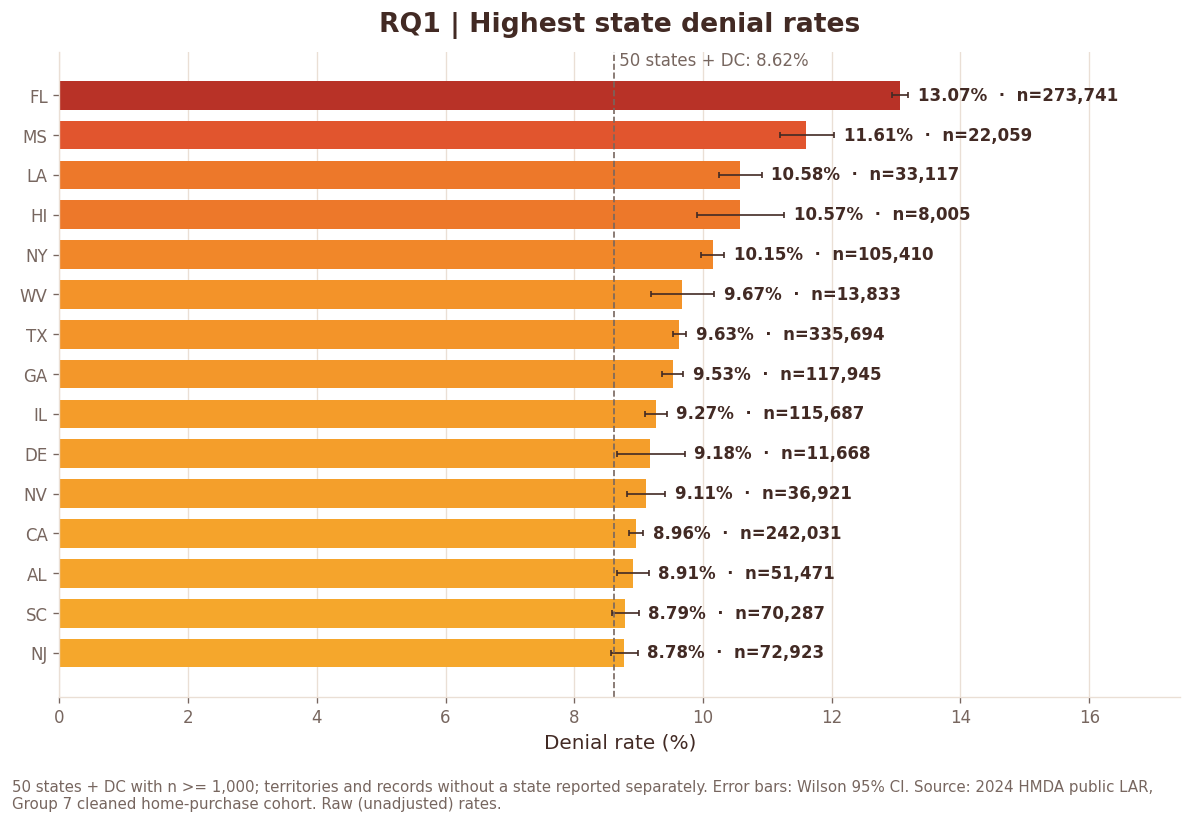

In [ ]:
# RQ1 support: 15 highest state denial rates (50 states + DC, n >= 1,000). Geographic scale: higher = darker
srep = TABLES["rq1_state_reportable"]
s = srep.query("n >= @STATE_FIG_MIN_N").head(15).iloc[::-1]
norm_st = plt.Normalize(srep["denial_rate_pct"].min(), srep["denial_rate_pct"].max())
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(s["state"], s["denial_rate_pct"], color=HEATMAP_CMAP(norm_st(s["denial_rate_pct"])), height=0.72)
ax.errorbar(s["denial_rate_pct"], s["state"], xerr=[s["denial_rate_pct"] - s["wilson_95_low_pct"],
            s["wilson_95_high_pct"] - s["denial_rate_pct"]], fmt="none", ecolor=COLORS["text"], elinewidth=1, capsize=2)
for _, r in s.iterrows():
    label(ax, r["wilson_95_high_pct"] + 0.15, r["state"], f"{r['denial_rate_pct']:.2f}%  ·  n={r['n']:,}", va="center")
ax.axvline(STATE_REF_PCT, color=COLORS["secondary"], ls="--", lw=1)
ax.text(STATE_REF_PCT, len(s) - 0.35, " " + REF_LABEL, fontsize=10, color=COLORS["secondary"], va="bottom")
ax.set_xlim(0, s["wilson_95_high_pct"].max() * 1.32)
style(ax, "RQ1 | Highest state denial rates", "Denial rate (%)", None, grid_axis="x")
save(fig, "rq1_01_state_denial_top15.png", "50 states + DC with n >= 1,000; territories and records without a state reported separately. Error bars: Wilson 95% CI.")

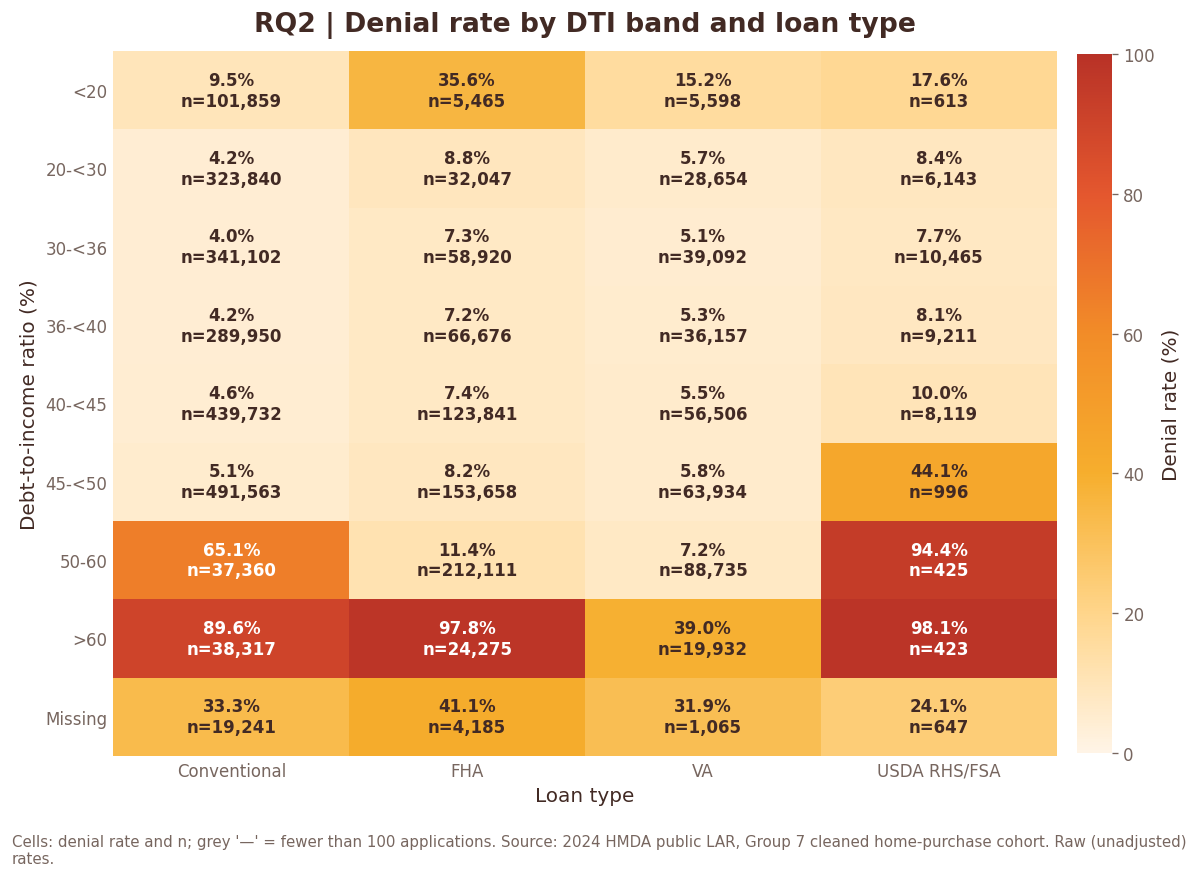

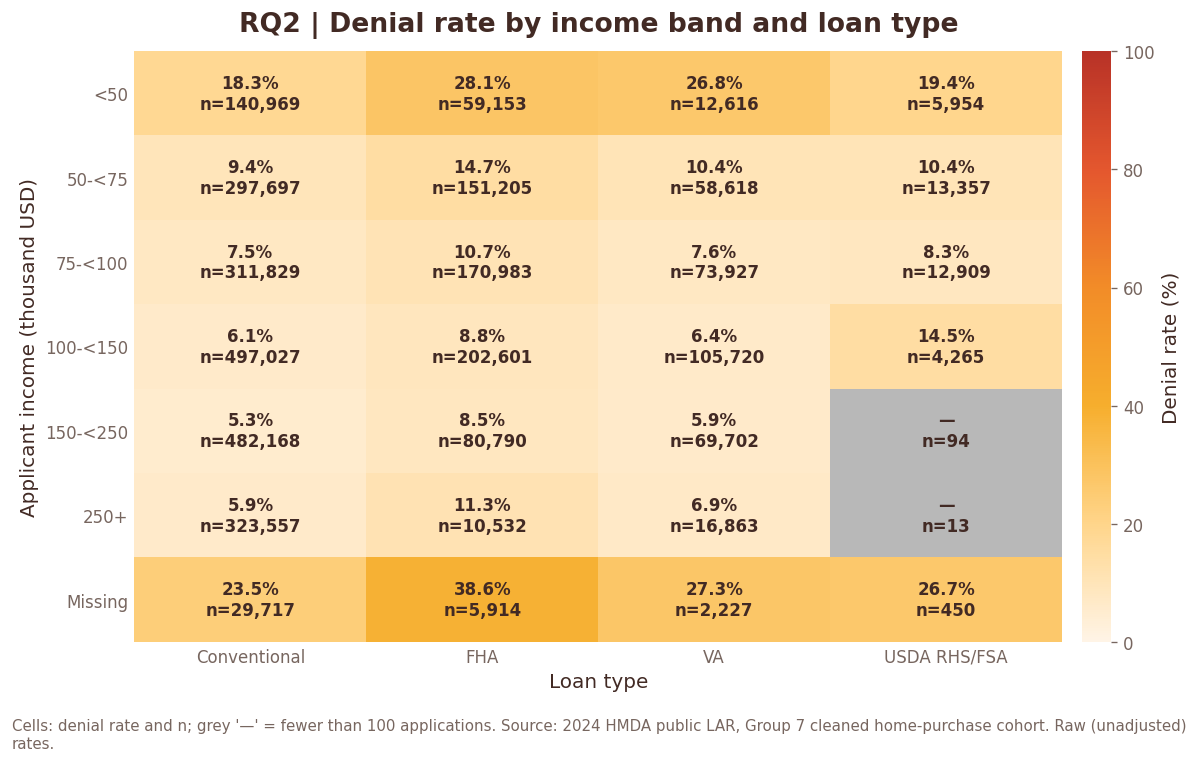

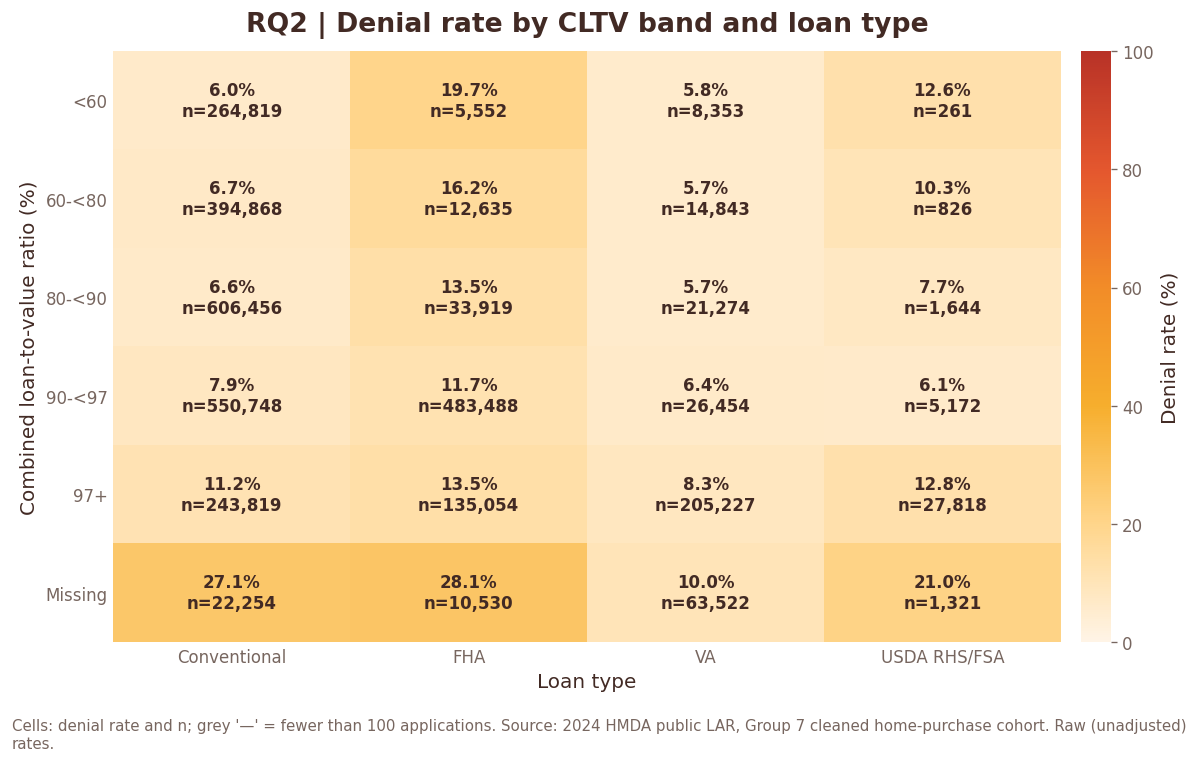

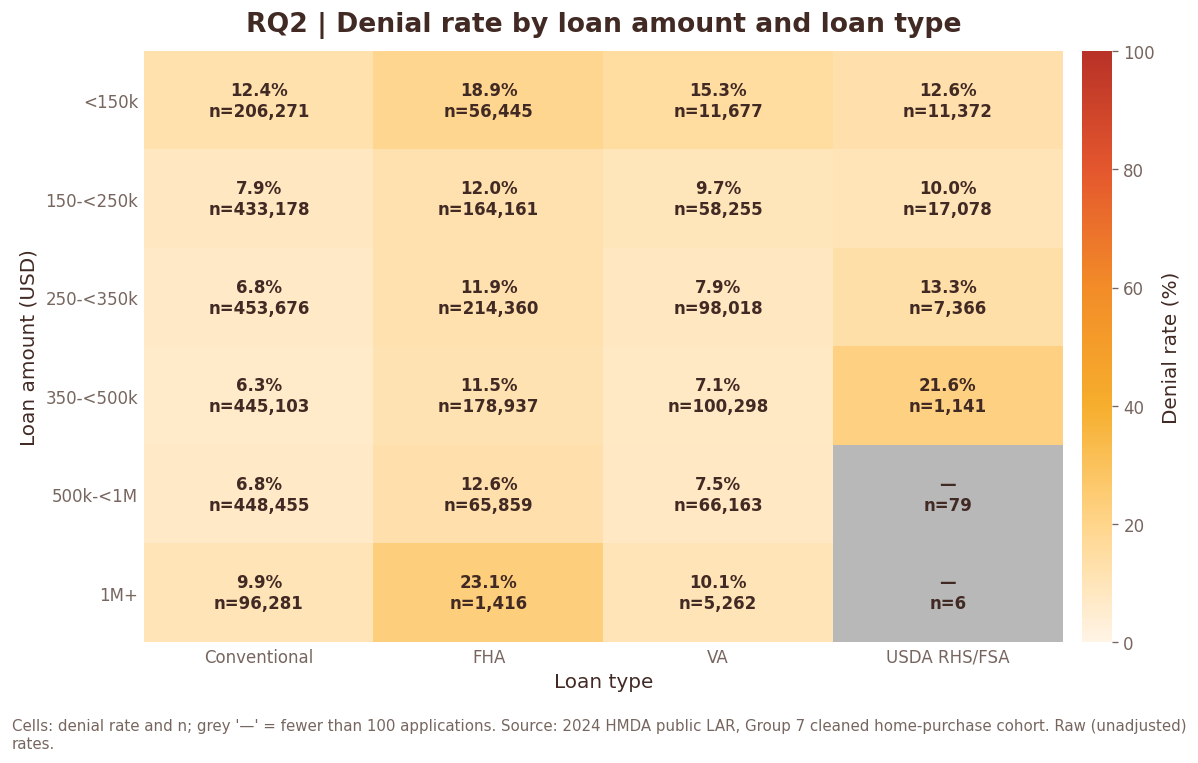

In [ ]:
# RQ2 heatmaps: denial rate by band and loan type (one color scale 0-100% for all)
def band_heatmap(table, band_col, order, title, ylabel, fname):
    t = table.set_index(["loan_type_name", band_col])
    rows = [b for b in order if b in set(table[band_col])]
    vals = np.full((len(rows), len(LOAN_TYPES)), np.nan); nv = vals.copy()
    for i, b in enumerate(rows):
        for j, lt in enumerate(LOAN_TYPES):
            if (lt, b) in t.index:
                nv[i, j] = t.loc[(lt, b), "n"]
                if bool(t.loc[(lt, b), "reportable"]):
                    vals[i, j] = t.loc[(lt, b), "denial_rate_pct"]
    heatmap(vals, nv, rows, LOAN_TYPES, title, "Loan type", ylabel, fname,
            "Cells: denial rate and n; grey '—' = fewer than 100 applications.", size=(10, max(6, 0.55 * len(rows) + 2)))

band_heatmap(TABLES["rq2_dti_by_loan_type"], "dti_cat", DTI_ORDER, "RQ2 | Denial rate by DTI band and loan type",
             "Debt-to-income ratio (%)", "rq2_01_dti_heatmap.png")
band_heatmap(TABLES["rq2_income_by_loan_type"], "income_band", INCOME_ORDER,
             "RQ2 | Denial rate by income band and loan type", "Applicant income (thousand USD)", "rq2_02_income_heatmap.png")
band_heatmap(TABLES["rq2_cltv_by_loan_type"], "cltv_band", CLTV_ORDER,
             "RQ2 | Denial rate by CLTV band and loan type", "Combined loan-to-value ratio (%)", "rq2_03_cltv_heatmap.png")
band_heatmap(TABLES["rq2_loan_amount_by_loan_type"], "loan_amount_band", LOAN_AMT_ORDER,
             "RQ2 | Denial rate by loan amount and loan type", "Loan amount (USD)", "rq2_04_loan_amount_heatmap.png")

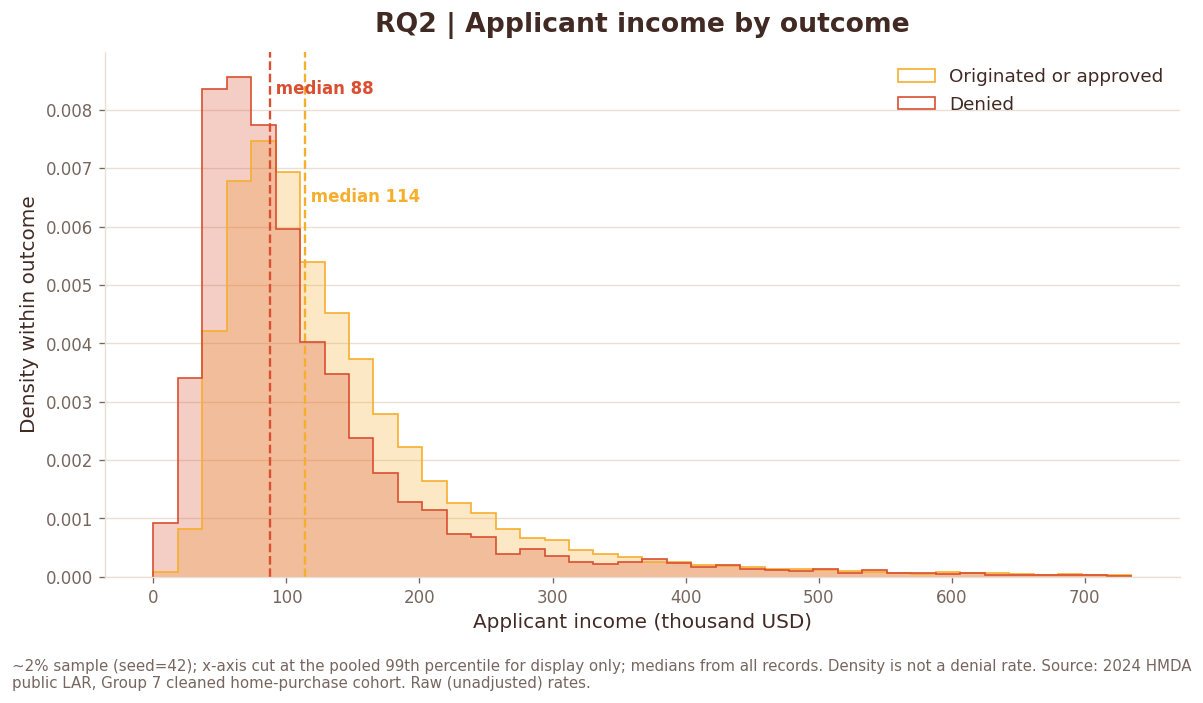

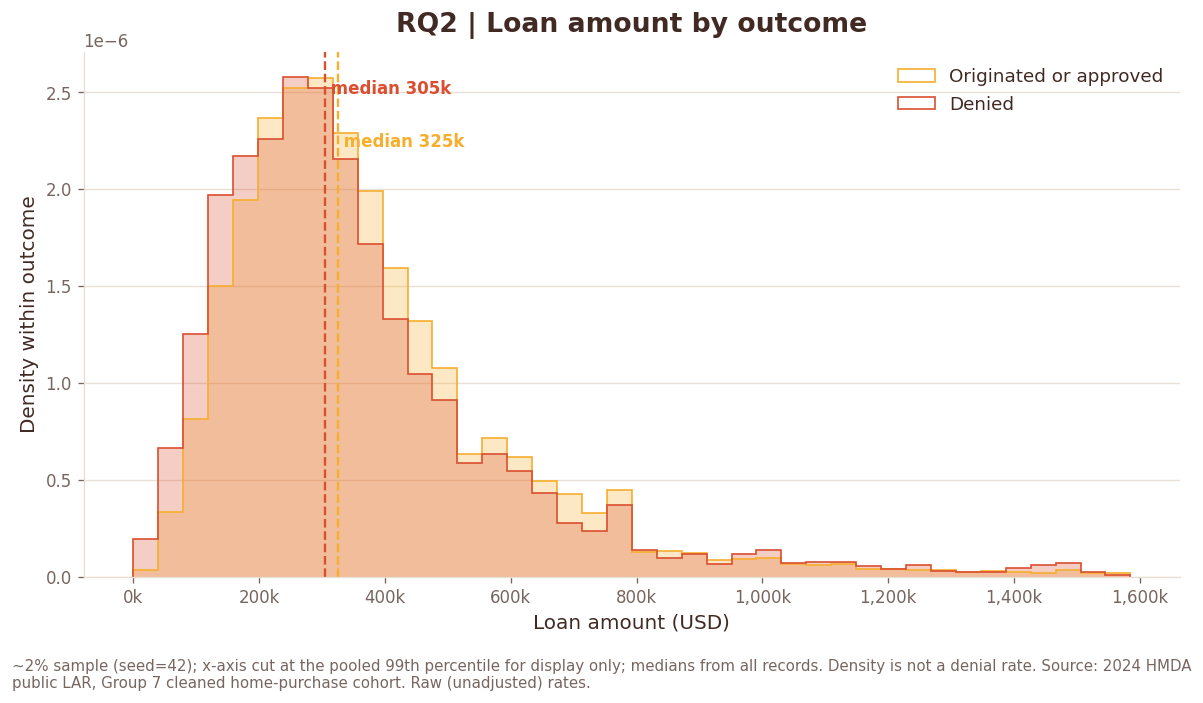

In [ ]:
# Distributions by outcome (reproducible ~2% sample; x-axis cut at the pooled 99th percentile for DISPLAY only)
sample = d.sample(frac=SAMPLE_FRAC, random_state=SEED)

def outcome_hist(col, xlabel, title, fname, fmt=None):
    x = sample[[col, "decision_group"]].dropna()
    cap = x[col].quantile(0.99)
    bins = np.linspace(0, cap, 41)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for grp in ["Originated/approved", "Denied"]:
        v = x.loc[(x["decision_group"] == grp) & (x[col] <= cap), col]
        c = OUTCOME_COLORS[OUTCOME_LABEL[grp]]
        ax.hist(v, bins=bins, density=True, histtype="stepfilled", color=c, alpha=0.28)
        ax.hist(v, bins=bins, density=True, histtype="step", color=c, lw=2.2, label=OUTCOME_LABEL[grp])
        med = d.loc[d["decision_group"] == grp, col].median()            # exact median of all records
        ax.axvline(med, color=c, ls="--", lw=1.4)
        txt = fmt(med) if fmt else f"{med:,.0f}"
        label(ax, med, ax.get_ylim()[1] * (0.92 if grp == "Denied" else 0.82), f" median {txt}", color=c)
    if fmt:
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: fmt(v)))
    ax.legend(frameon=False)
    style(ax, title, xlabel, "Density within outcome")
    save(fig, fname, f"~{SAMPLE_FRAC:.0%} sample (seed={SEED}); x-axis cut at the pooled 99th percentile for display only; "
                     "medians from all records. Density is not a denial rate.")

outcome_hist("income_kusd", "Applicant income (thousand USD)", "RQ2 | Applicant income by outcome", "rq2_05_income_distribution.png",
             fmt=lambda v: f"{v:,.0f}")
outcome_hist("loan_usd", "Loan amount (USD)", "RQ2 | Loan amount by outcome", "rq2_06_loan_distribution.png",
             fmt=lambda v: f"{v/1000:,.0f}k")

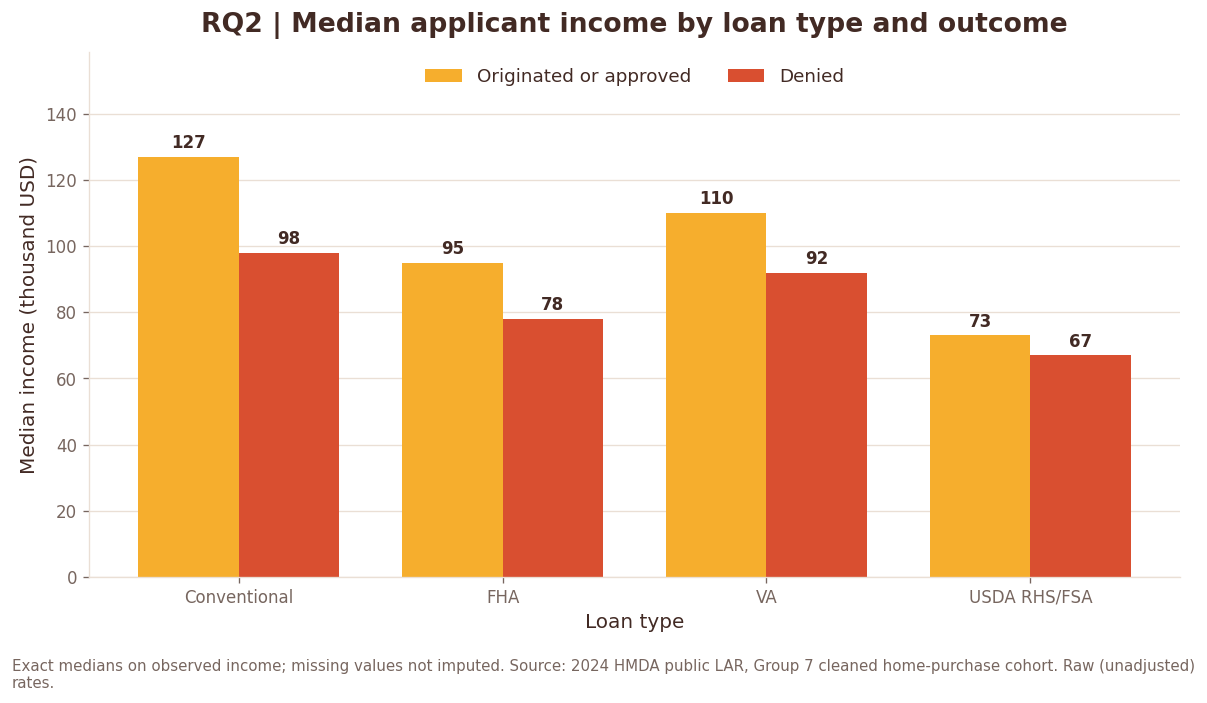

In [ ]:
# Median income by loan type and outcome
fp = TABLES["rq2_financial_profiles"]
fig, ax = plt.subplots(figsize=(10, 5.5))
w = 0.38
for k, grp in enumerate(["Originated/approved", "Denied"]):
    v = fp[fp["decision_group"] == grp].set_index("loan_type_name").reindex(LOAN_TYPES)["income_kusd_median"]
    xs = np.arange(len(LOAN_TYPES)) + (k - 0.5) * w
    ax.bar(xs, v, width=w, color=OUTCOME_COLORS[OUTCOME_LABEL[grp]], label=OUTCOME_LABEL[grp])
    for xi, vi in zip(xs, v):
        label(ax, xi, vi + 1.5, f"{vi:,.0f}", ha="center", va="bottom")
ax.set_xticks(range(len(LOAN_TYPES))); ax.set_xticklabels(LOAN_TYPES)
ax.set_ylim(0, fp["income_kusd_median"].max() * 1.25)
ax.legend(frameon=False, ncol=2, loc="upper center")
style(ax, "RQ2 | Median applicant income by loan type and outcome", "Loan type", "Median income (thousand USD)")
save(fig, "rq2_07_median_income.png", "Exact medians on observed income; missing values not imputed.")

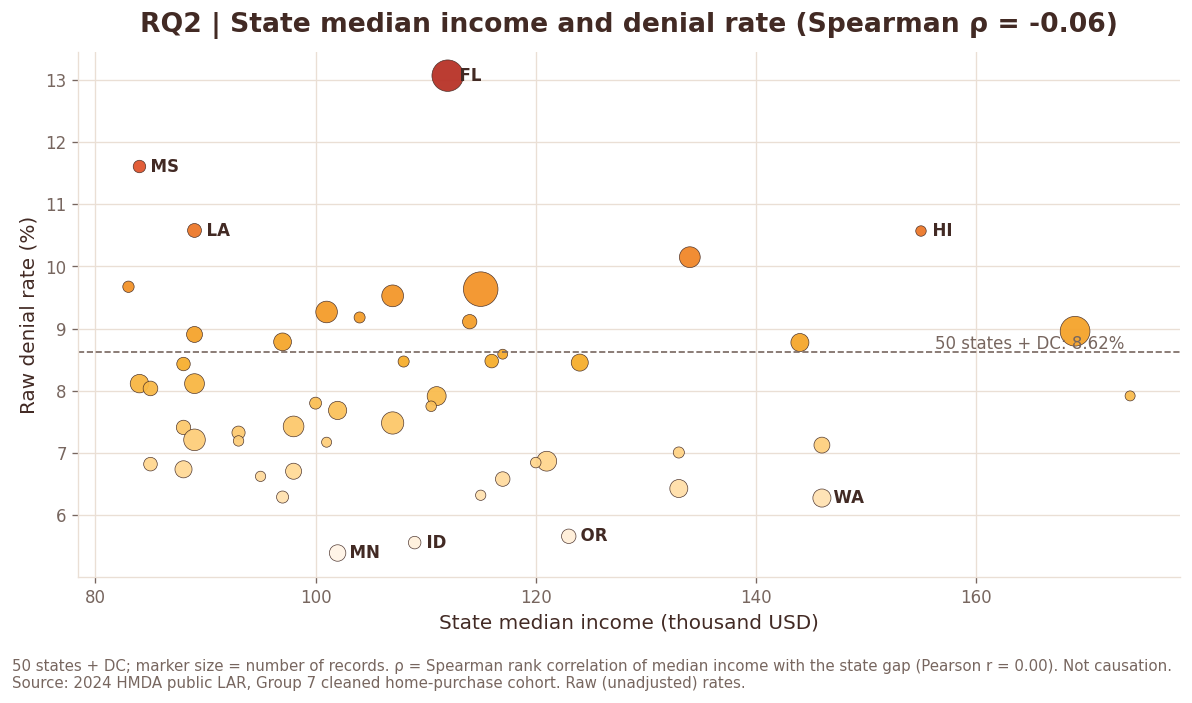

In [ ]:
# States: median income vs raw denial rate (geographic scale: higher denial = darker; size = number of records)
sp = TABLES["rq2_state_profiles_gap"]
norm = plt.Normalize(sp["denial_rate_pct"].min(), sp["denial_rate_pct"].max())
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(sp["income_kusd_median"], sp["denial_rate_pct"], s=30 + 400 * sp["n"] / sp["n"].max(),
           c=HEATMAP_CMAP(norm(sp["denial_rate_pct"])), edgecolor=COLORS["text"], linewidth=0.4, alpha=0.95)
ax.axhline(STATE_REF_PCT, color=COLORS["secondary"], ls="--", lw=1)
ax.text(sp["income_kusd_median"].max(), STATE_REF_PCT, REF_LABEL + " ", fontsize=10, color=COLORS["secondary"], ha="right", va="bottom")
for _, r in pd.concat([sp.head(4), sp.tail(4)]).iterrows():
    label(ax, r["income_kusd_median"], r["denial_rate_pct"], f"  {r['state']}", va="center")
rr = TABLES["rq2_state_gap_correlations"].set_index("indicator").loc["income_kusd_median"]
style(ax, f"RQ2 | State median income and denial rate (Spearman ρ = {rr['spearman_rho']:.2f})", "State median income (thousand USD)",
      "Raw denial rate (%)", grid_axis="both")
save(fig, "rq2_08_state_income_vs_denial.png", f"50 states + DC; marker size = number of records. ρ = Spearman rank correlation of median income with the state gap (Pearson r = {rr['pearson_r']:.2f}). Not causation.")

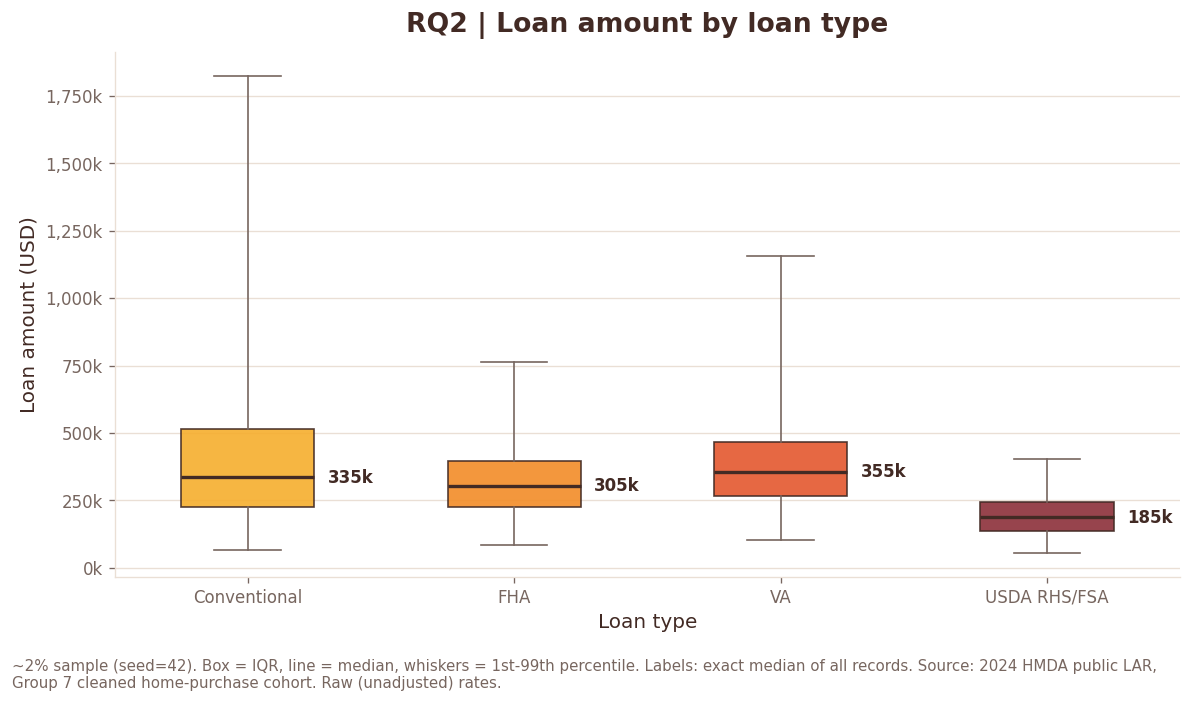

In [ ]:
# Loan amount by loan type (category colors). ~2% sample, whiskers 1st-99th percentile
fig, ax = plt.subplots(figsize=(10, 5.5))
data = [sample.loc[sample["loan_type_name"] == lt, "loan_usd"].dropna() for lt in LOAN_TYPES]
bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.5, whis=(1, 99),
                medianprops={"color": COLORS["text"], "lw": 2}, whiskerprops={"color": COLORS["secondary"]},
                capprops={"color": COLORS["secondary"]})
for patch, lt in zip(bp["boxes"], LOAN_TYPES):
    patch.set_facecolor(LOAN_TYPE_COLORS[lt]); patch.set_edgecolor(COLORS["text"]); patch.set_alpha(0.9)
for i, lt in enumerate(LOAN_TYPES):
    med = d.loc[d["loan_type_name"] == lt, "loan_usd"].median()
    label(ax, i + 1.3, med, f"{med/1000:,.0f}k", va="center")
ax.set_xticks(range(1, len(LOAN_TYPES) + 1)); ax.set_xticklabels(LOAN_TYPES)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v/1000:,.0f}k"))
style(ax, "RQ2 | Loan amount by loan type", "Loan type", "Loan amount (USD)")
save(fig, "rq2_09_loan_amount_boxplot.png", f"~{SAMPLE_FRAC:.0%} sample (seed={SEED}). Box = IQR, line = median, whiskers = 1st-99th percentile. Labels: exact median of all records.")

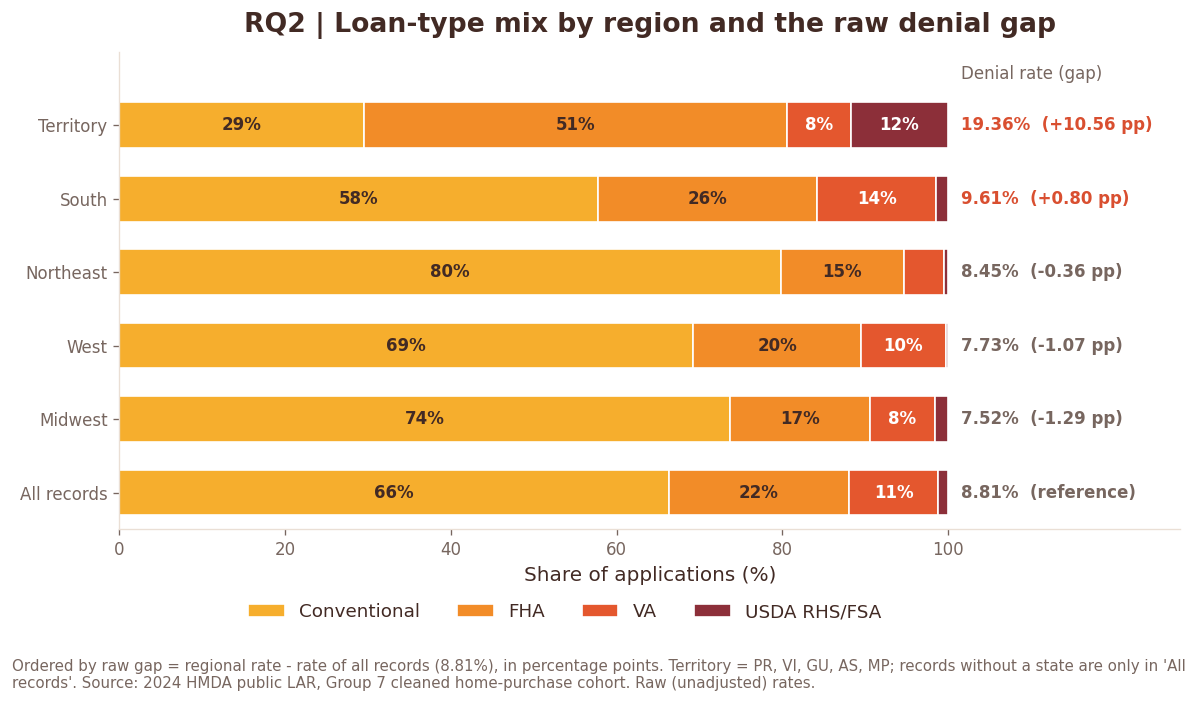

In [ ]:
# Loan-type mix by region, ordered by the raw gap (category colors)
rp = TABLES["rq2_region_profiles"]
order = rp[rp["census_region"] != ALL_RECORDS]["census_region"].tolist() + [ALL_RECORDS]
mix = rp.set_index("census_region").loc[order]
fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(order))
for lt, col in [("Conventional", "share_conventional_pct"), ("FHA", "share_fha_pct"), ("VA", "share_va_pct"),
                ("USDA RHS/FSA", "share_usda_pct")]:
    v = mix[col].to_numpy()
    ax.barh(range(len(order)), v, left=left, color=LOAN_TYPE_COLORS[lt], label=lt, height=0.62, edgecolor=COLORS["white"])
    for i, (l, vi) in enumerate(zip(left, v)):
        if vi >= 6:
            label(ax, l + vi / 2, i, f"{vi:.0f}%", ha="center", va="center",
                  color=COLORS["white"] if lt in ("VA", "USDA RHS/FSA") else COLORS["text"])
    left += v
for i, (name, r) in enumerate(mix.iterrows()):
    txt = f"{r['denial_rate_pct']:.2f}%  (reference)" if name == ALL_RECORDS else f"{r['denial_rate_pct']:.2f}%  ({r['gap_pp']:+.2f} pp)"
    label(ax, 101.5, i, txt, va="center", color=COLORS["denied"] if r["gap_pp"] > 0.005 else COLORS["secondary"])
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_ylim(len(order) - 0.5, -1.0)                                  # top row free for the column header
ax.set_xlim(0, 128); ax.set_xticks(range(0, 101, 20))
ax.text(101.5, -0.7, "Denial rate (gap)", fontsize=10, color=COLORS["secondary"], va="center")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.42, -0.12))
style(ax, "RQ2 | Loan-type mix by region and the raw denial gap", "Share of applications (%)", None, grid_axis=None)
save(fig, "rq2_10_region_loan_mix_gap.png", f"Ordered by raw gap = regional rate - rate of all records ({NAT_PCT:.2f}%), in percentage points. "
                                           "Territory = PR, VI, GU, AS, MP; records without a state are only in 'All records'.")

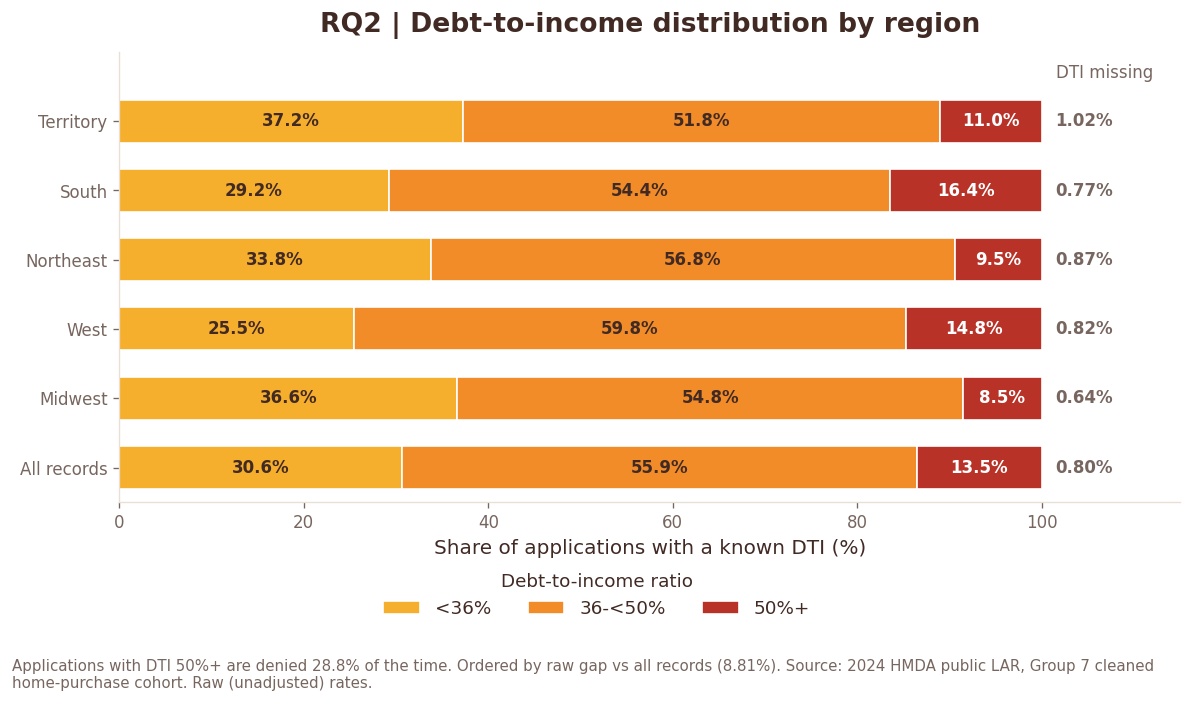

In [ ]:
# DTI distribution by region: shares among records with a known DTI (darker = higher DTI = higher denial); missing DTI at the right
DTI_VIEW = [("<36%", "share_dti_lt36_pct", COLORS["amber"]), ("36-<50%", "share_dti_36_50_pct", COLORS["orange"]),
            ("50%+", "share_dti_50plus_pct", COLORS["deep_red"])]
fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(order))
for name, col, c in DTI_VIEW:
    v = mix[col].to_numpy()
    ax.barh(range(len(order)), v, left=left, color=c, label=name, height=0.62, edgecolor=COLORS["white"])
    for i, (l, vi) in enumerate(zip(left, v)):
        if vi >= 5:
            label(ax, l + vi / 2, i, f"{vi:.1f}%", ha="center", va="center",
                  color=COLORS["white"] if c == COLORS["deep_red"] else COLORS["text"])
    left += v
for i, (_, r) in enumerate(mix.iterrows()):
    label(ax, 101.5, i, f"{r['share_dti_missing_pct']:.2f}%", va="center", color=COLORS["secondary"])
dti_all = TABLES["data_quality_dti_overall"].set_index("dti_cat")
r50 = 100 * dti_all.loc[["50-60", ">60"], "denied"].sum() / dti_all.loc[["50-60", ">60"], "n"].sum()
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_ylim(len(order) - 0.5, -1.0)
ax.set_xlim(0, 115); ax.set_xticks(range(0, 101, 20))
ax.text(101.5, -0.7, "DTI missing", fontsize=10, color=COLORS["secondary"], va="center")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.12), title="Debt-to-income ratio")
style(ax, "RQ2 | Debt-to-income distribution by region", "Share of applications with a known DTI (%)", None, grid_axis=None)
save(fig, "rq2_11_region_dti_distribution.png", f"Applications with DTI 50%+ are denied {r50:.1f}% of the time. Ordered by raw gap vs all records ({NAT_PCT:.2f}%).")

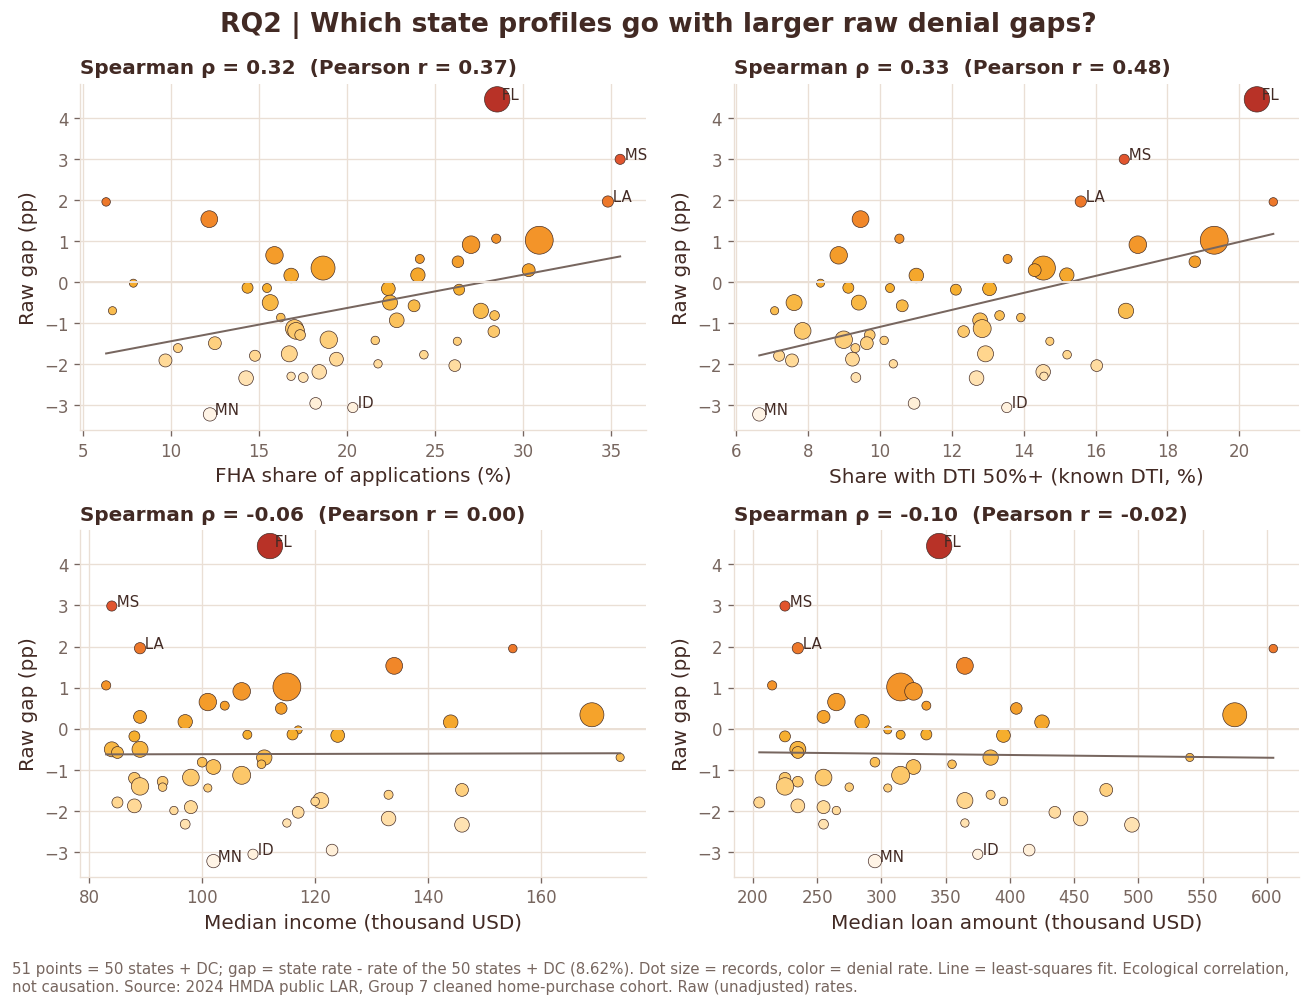

In [ ]:
# State gap vs four indicators (51 states). Geographic scale for the dots; main number = Spearman rho, Pearson in brackets
panels = [("share_fha_pct", "FHA share of applications (%)"), ("share_dti_50plus_pct", "Share with DTI 50%+ (known DTI, %)"),
          ("income_kusd_median", "Median income (thousand USD)"), ("loan_usd_median", "Median loan amount (thousand USD)")]
cr_ = TABLES["rq2_state_gap_correlations"].set_index("indicator")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (col, xl) in zip(axes.ravel(), panels):
    x = sp[col] / (1000 if col == "loan_usd_median" else 1)
    ax.scatter(x, sp["gap_pp"], s=20 + 260 * sp["n"] / sp["n"].max(), c=HEATMAP_CMAP(norm(sp["denial_rate_pct"])),
               edgecolor=COLORS["text"], linewidth=0.4)
    ok = x.notna()
    b1, b0 = np.polyfit(x[ok], sp.loc[ok, "gap_pp"], 1)
    xx = np.linspace(x.min(), x.max(), 50)
    ax.plot(xx, b0 + b1 * xx, color=COLORS["secondary"], lw=1.2)
    ax.axhline(0, color=COLORS["grid"], lw=1.2)
    for _, r in pd.concat([sp.head(3), sp.tail(2)]).iterrows():
        ax.text(r[col] / (1000 if col == "loan_usd_median" else 1), r["gap_pp"], f" {r['state']}", fontsize=9, color=COLORS["text"])
    ax.set_title(f"Spearman ρ = {cr_.loc[col, 'spearman_rho']:.2f}  (Pearson r = {cr_.loc[col, 'pearson_r']:.2f})", fontsize=12,
                 fontweight="semibold", color=COLORS["text"], loc="left")
    ax.set_xlabel(xl, fontsize=12, fontweight="medium")
    ax.set_ylabel("Raw gap (pp)", fontsize=12, fontweight="medium")
    ax.grid(color=COLORS["grid"], linewidth=0.8); ax.set_axisbelow(True)
fig.suptitle("RQ2 | Which state profiles go with larger raw denial gaps?", fontsize=16, fontweight="bold", color=COLORS["text"])
save(fig, "rq2_12_state_gap_indicators.png",
     f"{len(sp)} points = 50 states + DC; gap = state rate - rate of the 50 states + DC ({STATE_REF_PCT:.2f}%). Dot size = records, color = denial rate. "
     "Line = least-squares fit. Ecological correlation, not causation.")

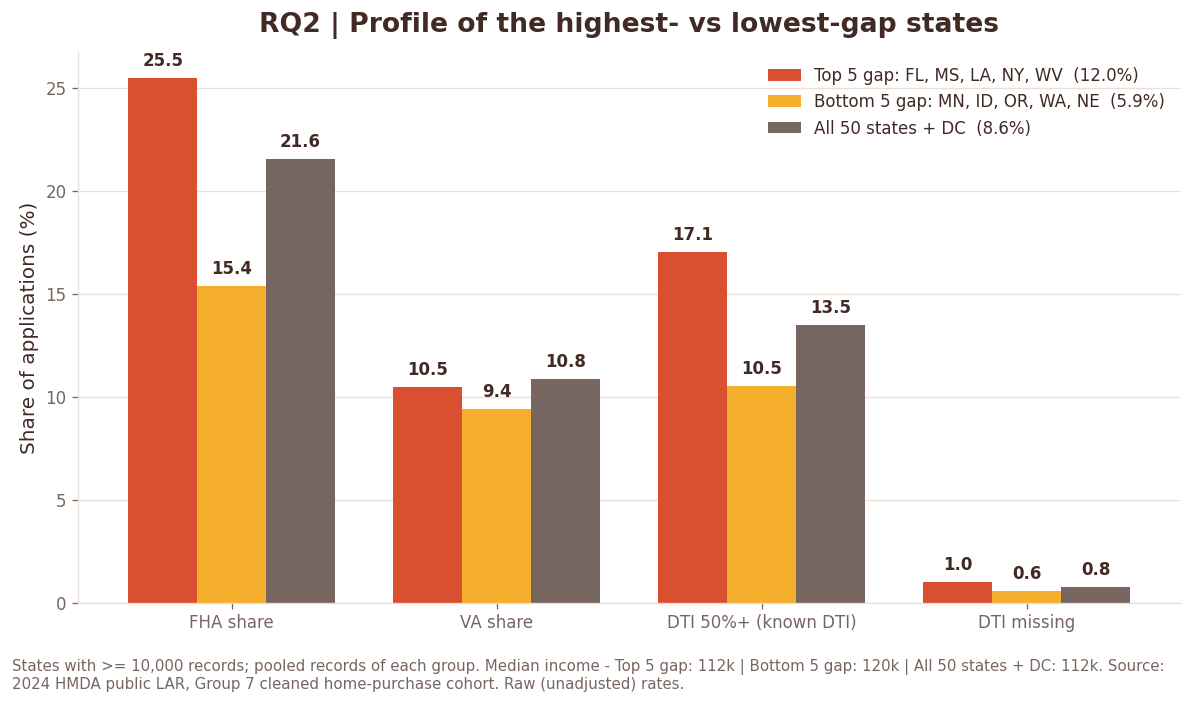

In [ ]:
# Top 5 vs bottom 5 gap states (red-orange = high-denial group, amber = comparison, grey-brown = all states)
ex = TABLES["rq2_gap_extremes"].set_index("group")
items = [("share_fha_pct", "FHA share"), ("share_va_pct", "VA share"), ("share_dti_50plus_pct", "DTI 50%+ (known DTI)"),
         ("share_dti_missing_pct", "DTI missing")]
groups = [("Top 5 gap", COLORS["denied"]), ("Bottom 5 gap", COLORS["amber"]), (ALL_STATES, COLORS["secondary"])]
fig, ax = plt.subplots(figsize=(10, 5.5))
w = 0.26
for k, (g, c) in enumerate(groups):
    v = [ex.loc[g, col] for col, _ in items]
    xs = np.arange(len(items)) + (k - 1) * w
    lab = f"{g}: {ex.loc[g, 'states']}" if g != ALL_STATES else g
    ax.bar(xs, v, width=w, color=c, label=f"{lab}  ({ex.loc[g, 'denial_rate_pct']:.1f}%)")
    for xi, vi in zip(xs, v):
        label(ax, xi, vi + 0.4, f"{vi:.1f}", ha="center", va="bottom")
ax.set_xticks(range(len(items))); ax.set_xticklabels([n for _, n in items])
ax.legend(frameon=False, fontsize=10, loc="upper right")
inc = " | ".join(f"{g}: {ex.loc[g, 'income_kusd_median']:.0f}k" for g, _ in groups)
style(ax, "RQ2 | Profile of the highest- vs lowest-gap states", None, "Share of applications (%)")
save(fig, "rq2_13_gap_extremes.png", f"States with >= {GAP_MIN_N:,} records; pooled records of each group. Median income - {inc}.")

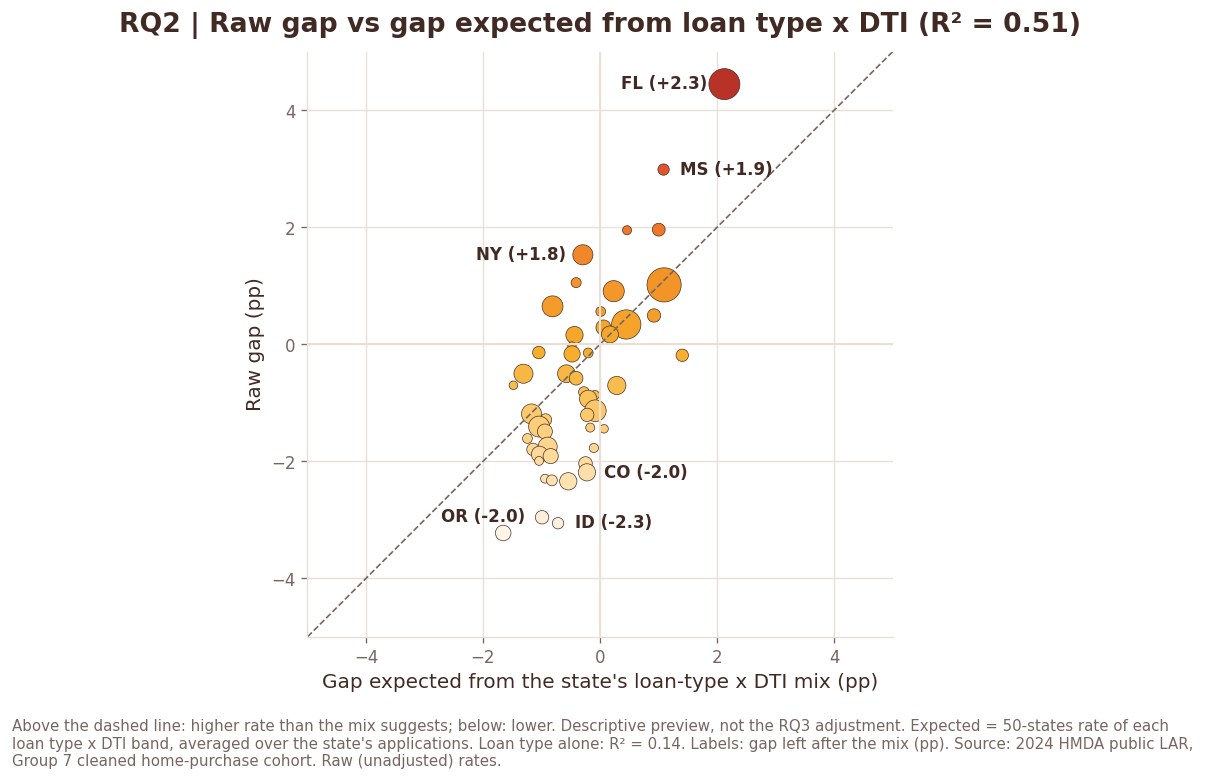

In [ ]:
# NEW - Raw gap vs gap expected from the loan-type x DTI mix (points on the dashed line: the mix alone matches the raw gap)
pv = TABLES["rq2_state_gap_mix_preview"]
msum = TABLES["rq2_gap_mix_summary"].set_index("mix")
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(pv["exp_gap_loan_type_dti_pp"], pv["raw_gap_pp"], s=20 + 400 * pv["n"] / pv["n"].max(),
           c=HEATMAP_CMAP(norm(pv["denial_rate_pct"])), edgecolor=COLORS["text"], linewidth=0.4)
lim = np.ceil(max(pv["raw_gap_pp"].abs().max(), pv["exp_gap_loan_type_dti_pp"].abs().max()) + 0.5)
ax.plot([-lim, lim], [-lim, lim], color=COLORS["secondary"], ls="--", lw=1)
ax.axhline(0, color=COLORS["grid"], lw=1.2); ax.axvline(0, color=COLORS["grid"], lw=1.2)
far = pv.reindex(pv["resid_gap_loan_type_dti_pp"].abs().sort_values(ascending=False).index).head(6)
for k, (_, r) in enumerate(far.sort_values("raw_gap_pp").iterrows()):
    right = k % 2 == 0                                                   # alternate sides so close points do not overlap
    ax.annotate(f"{r['state']} ({r['resid_gap_loan_type_dti_pp']:+.1f})", (r["exp_gap_loan_type_dti_pp"], r["raw_gap_pp"]),
                xytext=(10 if right else -10, 0), textcoords="offset points", ha="left" if right else "right", va="center",
                fontsize=10, fontweight="semibold", color=COLORS["text"])
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
r2 = msum.loc["loan type x DTI band", "r_squared"]; r2l = msum.loc["loan type", "r_squared"]
style(ax, f"RQ2 | Raw gap vs gap expected from loan type x DTI (R² = {r2:.2f})",
      "Gap expected from the state's loan-type x DTI mix (pp)", "Raw gap (pp)", grid_axis="both")
save(fig, "rq2_14_gap_mix_preview.png",
     f"Above the dashed line: higher rate than the mix suggests; below: lower. Descriptive preview, not the RQ3 adjustment. Expected = 50-states rate of each loan type x DTI band, averaged over the state's applications. "
     f"Loan type alone: R² = {r2l:.2f}. Labels: gap left after the mix (pp).")

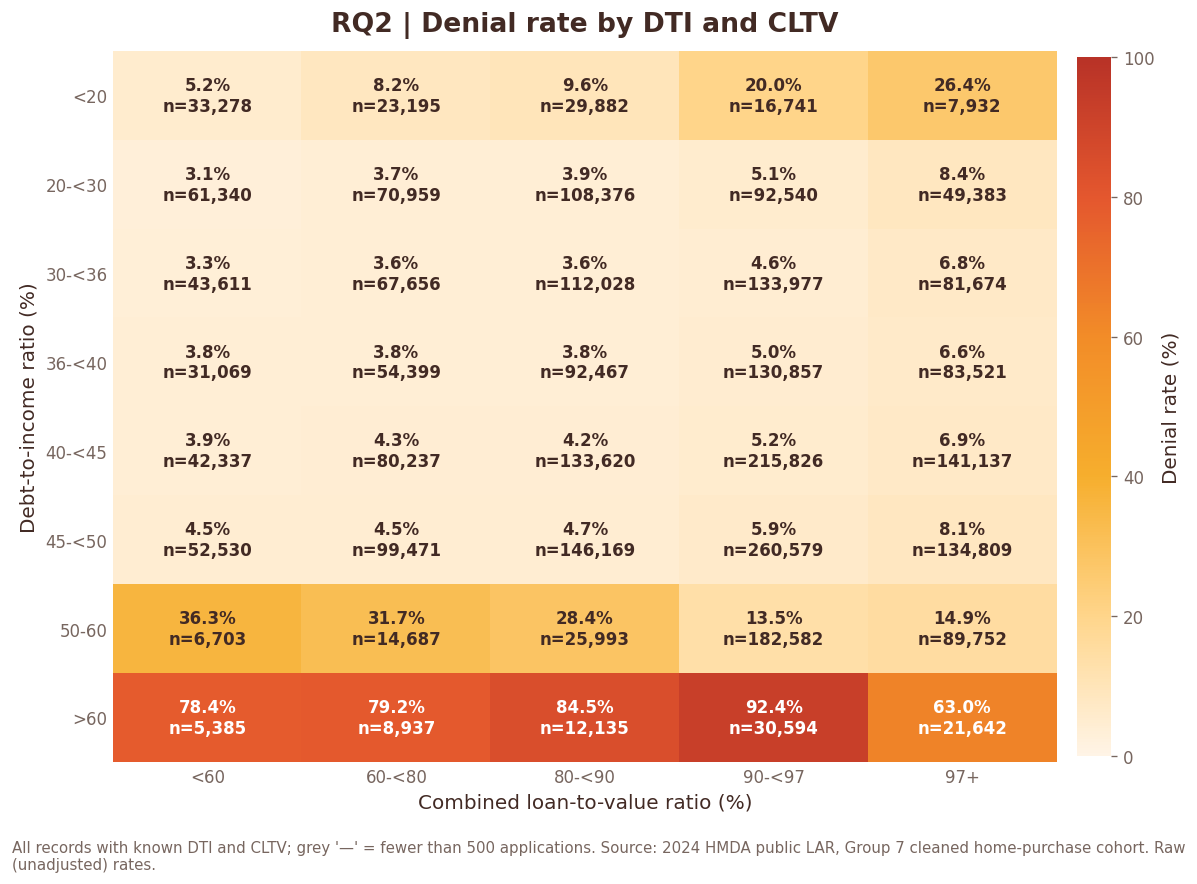

In [ ]:
# NEW - Denial rate by DTI x CLTV (cells with fewer than 500 records in grey)
dcx = TABLES["rq2_dti_x_cltv"].set_index(["dti_cat", "cltv_band"])
rows_ = [b for b in DTI_ORDER if b != "Missing"]; cols_ = [b for b in CLTV_ORDER if b != "Missing"]
vals = np.full((len(rows_), len(cols_)), np.nan); nv = vals.copy()
for i, a in enumerate(rows_):
    for j, b in enumerate(cols_):
        if (a, b) in dcx.index:
            nv[i, j] = dcx.loc[(a, b), "n"]
            if bool(dcx.loc[(a, b), "shown"]):
                vals[i, j] = dcx.loc[(a, b), "denial_rate_pct"]
heatmap(vals, nv, rows_, cols_, "RQ2 | Denial rate by DTI and CLTV", "Combined loan-to-value ratio (%)",
        "Debt-to-income ratio (%)", "rq2_15_dti_cltv_heatmap.png",
        f"All records with known DTI and CLTV; grey '—' = fewer than {MIN_CELL} applications.", size=(10, 7))

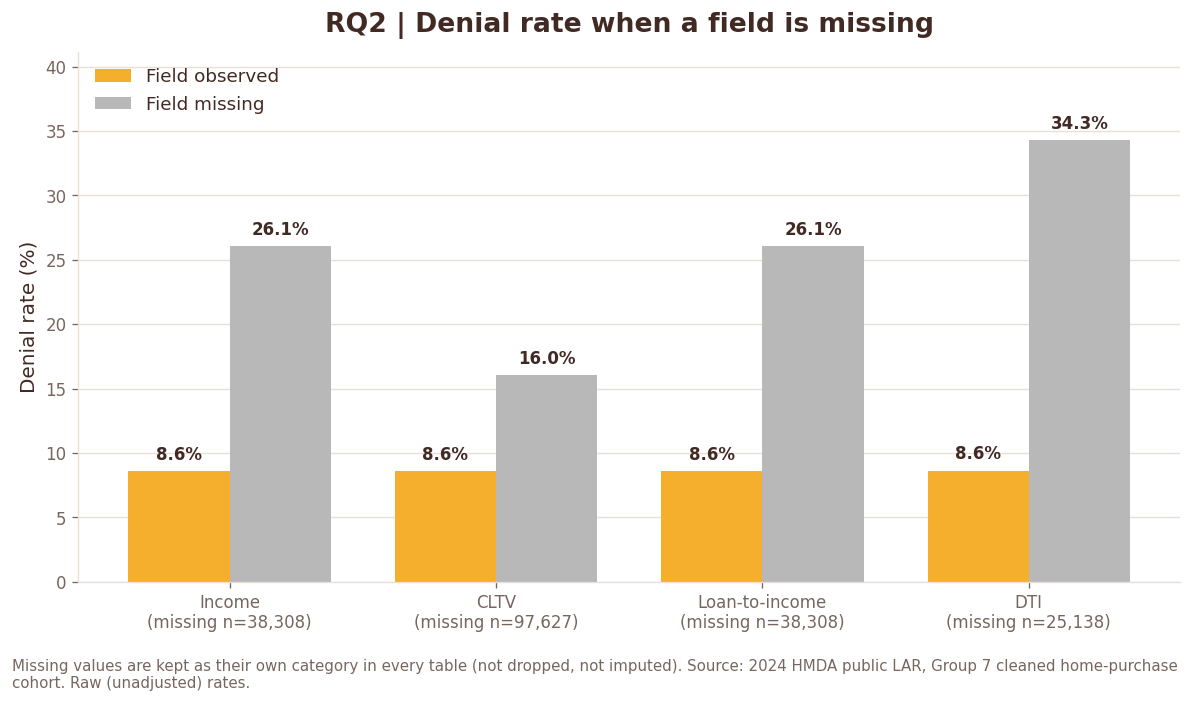

In [ ]:
# NEW - Denial rate when a field is missing vs observed (missing = grey, observed = amber)
mv_ = TABLES["rq2_missingness_vs_denial"]
fig, ax = plt.subplots(figsize=(10, 5.5))
w = 0.38
xs = np.arange(len(mv_))
ax.bar(xs - w / 2, mv_["denial_rate_if_observed_pct"], width=w, color=COLORS["amber"], label="Field observed")
ax.bar(xs + w / 2, mv_["denial_rate_if_missing_pct"], width=w, color=COLORS["missing"], label="Field missing")
for xi, (_, r) in zip(xs, mv_.iterrows()):
    label(ax, xi - w / 2, r["denial_rate_if_observed_pct"] + 0.6, f"{r['denial_rate_if_observed_pct']:.1f}%", ha="center", va="bottom")
    label(ax, xi + w / 2, r["denial_rate_if_missing_pct"] + 0.6, f"{r['denial_rate_if_missing_pct']:.1f}%", ha="center", va="bottom")
ax.set_xticks(xs); ax.set_xticklabels([f"{f}\n(missing n={n:,})" for f, n in zip(mv_["field"], mv_["missing_n"])])
ax.set_ylim(0, mv_["denial_rate_if_missing_pct"].max() * 1.2)
ax.legend(frameon=False, loc="upper left")
style(ax, "RQ2 | Denial rate when a field is missing", None, "Denial rate (%)")
save(fig, "rq2_16_missing_vs_denial.png", "Missing values are kept as their own category in every table (not dropped, not imputed).")

## Step 9. Part F - Save tables, manifest and zip

In [ ]:
for name, t in TABLES.items():
    t.to_csv(f"{OUT_DIR}/{name}.csv", index=False)

SPARK_CHECK = f"{RESULTS_DIR}/rq2_spark/pandas_spark_correctness_rq2.csv"
if os.path.exists(SPARK_CHECK):
    corr = pd.read_csv(SPARK_CHECK)
else:
    corr = pd.DataFrame([{"test": "Pandas-PySpark", "status": "PENDING",
                          "details": "run notebook 05 (PySpark check) after this notebook"}])
corr.to_csv(f"{OUT_DIR}/pandas_spark_correctness.csv", index=False)

manifest = {
    "source": "Group 7 cleaned 2024 HMDA home-purchase cohort (hmda_clean_v1)",
    "cohort_n": int(len(d)), "denied_n": int(d["denied"].sum()), "overall_denial_rate_pct": NAT_PCT,
    "reference_rule": "reference = pooled rate of exactly the group being compared",
    "state_reference_pct": STATE_REF_PCT, "state_reference": "50 states + DC (3,119,941 records): state gaps, rankings, correlations, mix preview, state figures",
    "all_records_reference_pct": NAT_PCT, "all_records_reference": "all records (3,140,857): regions, loan types, metro status, MSAs",
    "gap_definition": "raw rate of the group minus its reference rate, percentage points",
    "geographic_comparison": "50 states + DC; territories in rq1_territories; records without a state in rq1_state_missing_summary",
    "bands": "cleaning-rule bands of hmda_clean_v1 (not re-binned)",
    "dti_denominator": "profile DTI shares among records with a known DTI (0.80% missing excluded); share_dti_missing_pct and rq2_region_dti_distribution over all records",
    "subgroup_min_n": MIN_N, "two_way_cell_min_n": MIN_CELL, "msa_min_n": MSA_MIN_N, "gap_extremes_min_n": GAP_MIN_N,
    "financial_median": "Pandas exact, observed non-missing values only",
    "hist_sample": f"reproducible ~{SAMPLE_FRAC:.0%} sample, random_state={SEED}; x-axis 99th percentile for DISPLAY only",
    "benchmark": "notebook 03 only (not in this notebook); the report uses the figure of notebook 03",
    "correlation_main": "Spearman rho across 51 states; Pearson and record-weighted Pearson are secondary",
    "spark_crosscheck": "notebook 05 -> results/rq2_spark/pandas_spark_correctness_rq2.csv",
    "figures": FIGURES, "csv_tables": [f"{k}.csv" for k in TABLES] + ["pandas_spark_correctness.csv"],
    "limitations": ["No causal inference", "Correlations across states are ecological",
                    "Missing CLTV/income/DTI go with higher denial (kept as a category)",
                    "Raw gaps only; the mix preview is descriptive and the adjusted gaps are RQ3"],
}
with open(f"{OUT_DIR}/manifest.json", "w") as fh:
    json.dump(manifest, fh, indent=2, default=float)

zpath = f"{OUT_DIR}/GROUP7_RQ1_RQ2_FINAL_OUTPUTS.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f"{OUT_DIR}/*.csv") + glob.glob(f"{OUT_DIR}/*.json") + glob.glob(f"{FIG_DIR}/*.png"):
        z.write(f, os.path.relpath(f, OUT_DIR))
check("figures saved (= 17 in the header)", len(FIGURES), 17)
print(f"Saved {len(TABLES)} tables + {len(FIGURES)} figures to {OUT_DIR}")
print("Zip:", zpath)

OK        figures saved (= 17 in the header)             got=          17  expected=          17
Saved 37 tables + 17 figures to /content/drive/MyDrive/hmda/results/rq1_rq2_pandas
Zip: /content/drive/MyDrive/hmda/results/rq1_rq2_pandas/GROUP7_RQ1_RQ2_FINAL_OUTPUTS.zip


In [ ]:
chk = pd.DataFrame(CHECKS, dtype=object)
print(chk.to_string(index=False))
print(f"\n{(chk['status'] == 'OK').sum()} of {len(chk)} checks OK")

                                        check     got expected status
                                  clean: rows 3140857  3140857     OK
                                clean: denied  276604   276604     OK
                      records without a state    8026     8026     OK
                       records in territories   12890    12890     OK
                    records in 50 states + DC 3119941  3119941     OK
                     denied in 50 states + DC  268873   268873     OK
                    loan types without a name       0        0     OK
  CLTV missing, originated (%) = proposal 2.7     2.7      2.7     OK
CLTV missing, approved not accepted (%) = 7.0     7.0      7.0     OK
                         RQ1 states (50 + DC)      51       51     OK
                     RQ1 MSAs with n >= 5,000     134      134     OK
      cross-check: Spearman, share DTI >= 50%    0.33     0.33     OK
         cross-check: Spearman, median income   -0.06    -0.06     OK
    cross-check: Spe